In [ ]:
import random
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from keras import models, layers, callbacks
import keras_tuner
from keras_tuner import RandomSearch, Hyperband, BayesianOptimization

In [26]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [ ]:
current_dir = Path.cwd()

## Checking best hiper-parameters

In [ ]:
desc_dim = 887
emb_dim = 1024
dtype = tf.float32
data_path = str(current_dir.parent / 'datasets/Second_Level/')
output_path = str(current_dir.parent / 'models/Second_Level/')
embs_path = data_path + 'valid_emb.npy'
feats_path = data_path + 'valid_feat.npy'
labels_path = data_path + 'y_valid.npy'

In [3]:

def build_model(hp) -> keras.Model:
    input_desc = layers.Input(shape=(desc_dim,), dtype=dtype)
    input_emb = layers.Input(shape=(emb_dim,), dtype=dtype)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_emb = layers.GaussianNoise(noise_std)(input_emb)
    noisy_desc = layers.GaussianNoise(noise_std)(input_desc)

    #y = input_emb
    y = noisy_emb
    units_e = hp.Int(f'emb_units_start', min_value=256, max_value=768, step=64)
    for i in range(hp.Int('emb_layers', 1, 3)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    #x = input_desc
    x = noisy_desc
    units_d = hp.Int(f'desc_units_start', min_value=128, max_value=512, step=64)
    for i in range(hp.Int('desc_layers', 1, 3)):
        x = layers.Dense(units_d // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.Dropout(dropout_rate)(x)

    combined = layers.Concatenate()([y, x])
    
    z = combined
    units_h = hp.Int(f'head_units_start', min_value=64, max_value=256, step=64)
    num_layers = hp.Int('head_layers', 1, 3)
    for i in range(num_layers):
        z = layers.Dense(units_h // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(z)
        z = layers.BatchNormalization()(z)
        z = layers.Activation(activation)(z)
        if i + 1 != num_layers:
            z = layers.Dropout(dropout_rate)(z)

    z = layers.Dense(7)(z)
    output = layers.Activation('softmax')(z)
    model = models.Model([input_emb, input_desc], output, name='classifier_2l')
    learning_rate = hp.Float('learning_rate', min_value=1e-6, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=[metrics.AUC(curve='ROC', multi_label=True), metrics.F1Score(average='macro')]
    )
    return model

In [4]:
tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_SL',
        project_name='enzyme_dual_branch'
    )

Reloading Tuner from tunning_SL\enzyme_dual_branch\tuner0.json


In [5]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")

Best Hyperparameters:
dropout_rate: 0.1
activation: leaky_relu
l2_reg: 1.1178850451720918e-05
noise_std: 0.09999999999999999
emb_units_start: 576
emb_layers: 3
desc_units_start: 448
desc_layers: 2
head_units_start: 128
head_layers: 1
learning_rate: 2.432637260796817e-05
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 1
tuner/round: 1
tuner/trial_id: 0081


## Check training results

In [4]:
tf.keras.mixed_precision.set_global_policy('float64')

In [5]:
tf.random.set_seed(42)

In [ ]:
training_dir = str(current_dir.parent / 'notebooks/2L_train/')
train_emb_dir = training_dir + 'train_emb.npy'
train_feat_dir = training_dir + 'train_feat.npy'
y_train_dir = training_dir + 'y_train.npy'
valid_emb_dir = training_dir + 'valid_emb.npy'
valid_feat_dir = training_dir + 'valid_feat.npy'
y_valid_dir = training_dir + 'y_valid.npy'
model_dir = training_dir + 'model.keras'
history_dir = training_dir + 'history.csv'
num_class = 7
test_emb_dir = str(current_dir.parent / 'datasets/Second_Level/test_emb.npy')
test_feat_dir = str(current_dir.parent / 'datasets/Second_Level/test_feat.npy')
y_test_dir = str(current_dir.parent / 'datasets/Second_Level/y_test.npy')

In [29]:
y_train = np.load(y_train_dir)
y_valid = np.load(y_valid_dir)
y_test = np.load(y_test_dir)

In [10]:
print(np.sum(y_train, axis=0))
print(np.sum(y_valid, axis=0))
print(np.sum(y_test, axis=0))
print(len(y_train), len(y_valid), len(y_test))

[18091. 54075. 27627. 15299.  9563. 18099.  5901.]
[2262. 6760. 3453. 1912. 1195. 2262.  738.]
[2261. 6759. 3453. 1913. 1196. 2263.  737.]
148655 18582 18582


In [30]:
history = pd.read_csv(history_dir)
history.head(12)

,epoch,auc,f1_score,loss,val_auc,val_f1_score,val_loss
0,0,0.820967,0.725211,0.796056,0.896091,0.831724,0.543354
1,1,0.919196,0.873428,0.397417,0.926550,0.882341,0.399071
2,2,0.946572,0.916498,0.270380,0.935402,0.896997,0.359997
3,3,0.961434,0.939861,0.199526,0.940313,0.905317,0.352362
4,4,0.970407,0.953613,0.155933,0.942862,0.911437,0.359031
5,5,0.976138,0.962447,0.127288,0.946307,0.914824,0.377782
6,6,0.980068,0.968606,0.108518,0.948731,0.919003,0.394366
7,7,0.982578,0.972052,0.094337,0.947736,0.914226,0.450966
8,8,0.984198,0.974738,0.085603,0.946242,0.915862,0.464811
9,9,0.986033,0.977729,0.076676,0.947461,0.915202,0.514567


In [31]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: dict, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

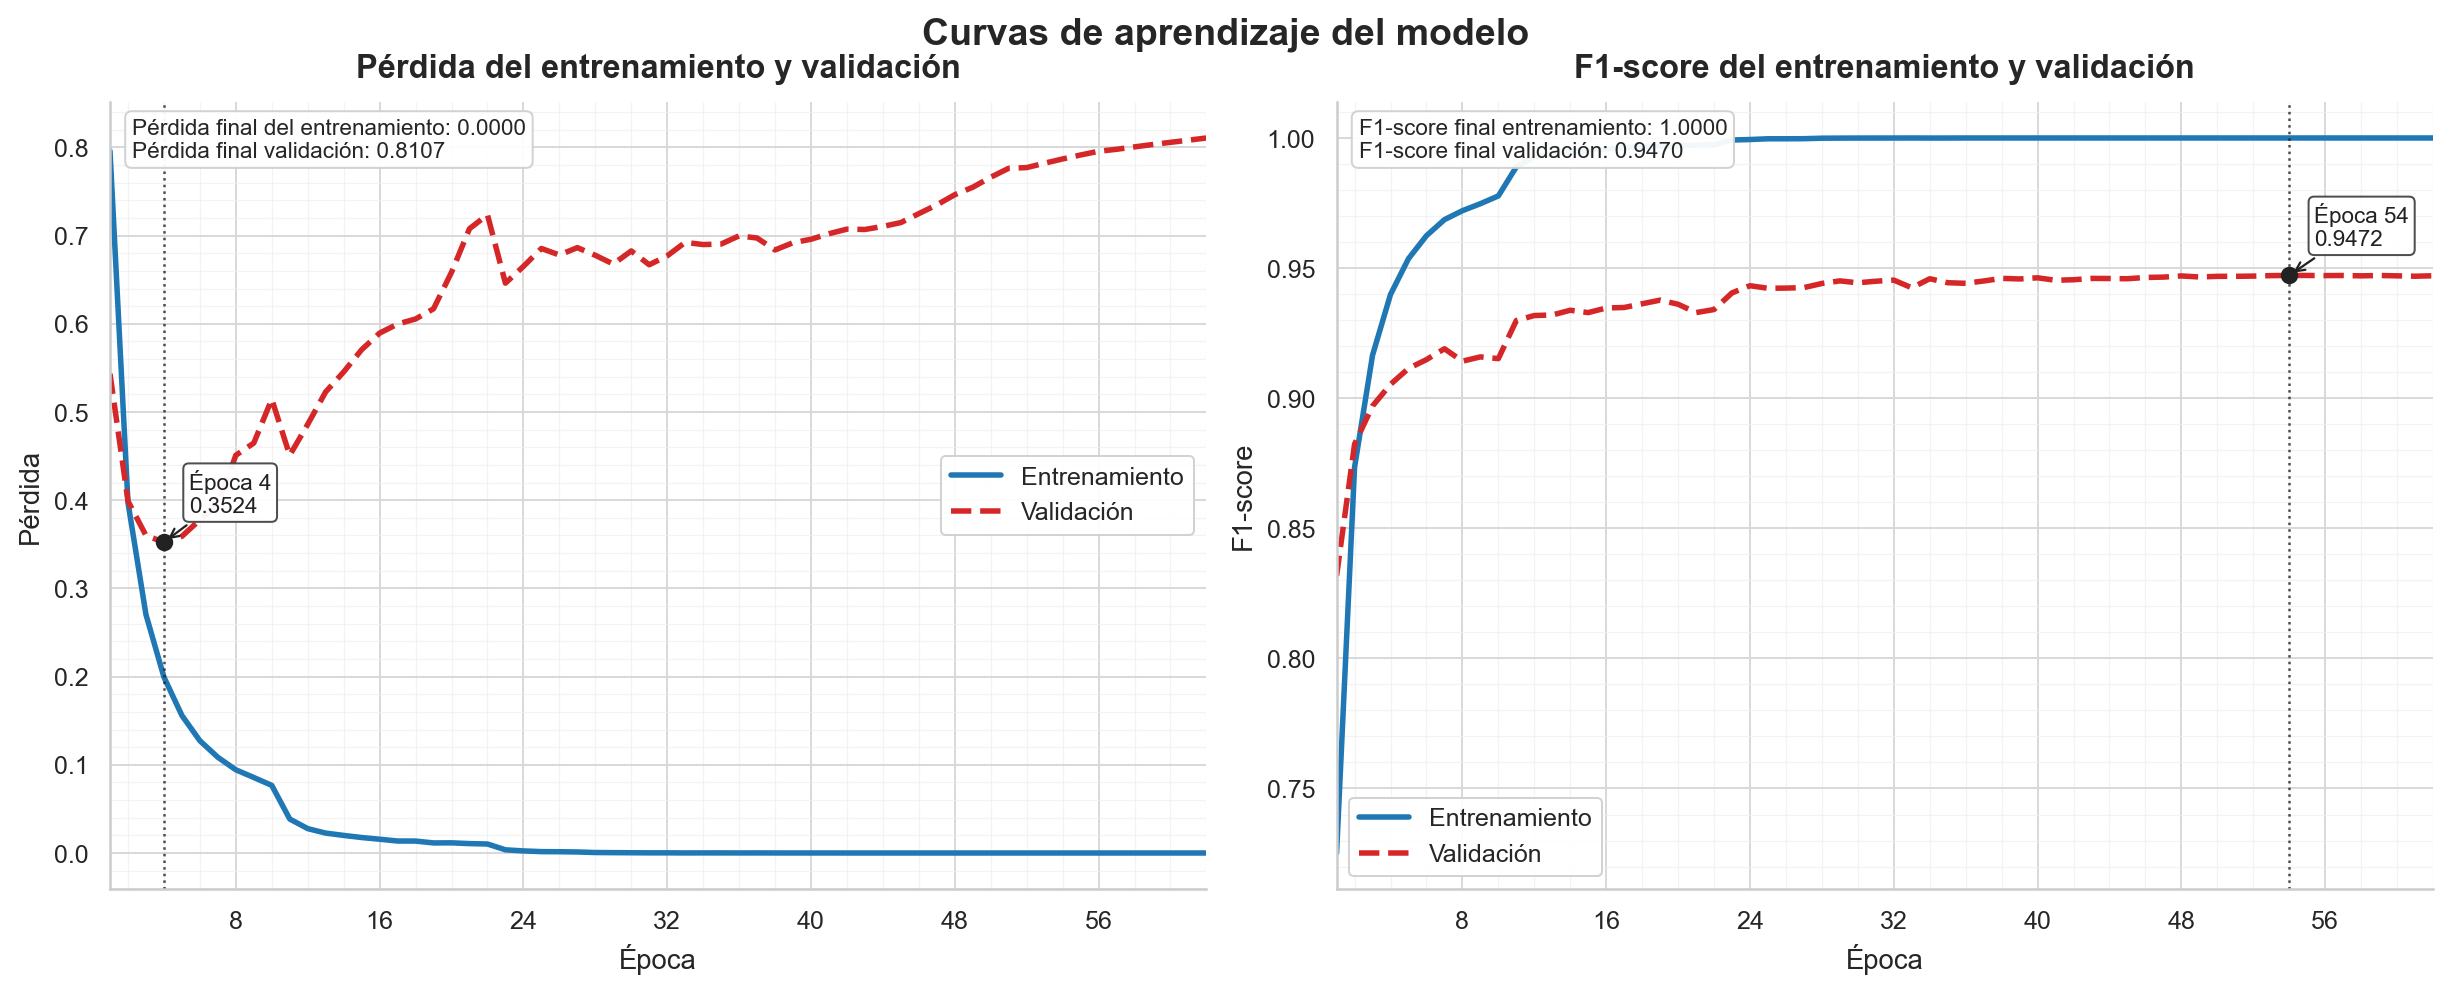

In [32]:
from matplotlib.ticker import MaxNLocator

epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

best_val_loss_idx = history['val_loss'].idxmin()
best_val_acc_idx = history['val_f1_score'].idxmax()

train_color = '#1f77b4'
valid_color = '#d62728'
highlight_color = '#222222'

sns.set_theme(style='whitegrid', context='paper')
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

metric_specs = [
    {
        'ax': axes[0],
        'train_key': 'loss',
        'valid_key': 'val_loss',
        'title': 'Pérdida del entrenamiento y validación',
        'ylabel': 'Pérdida',
        'best_idx': best_val_loss_idx,
    },
    {
        'ax': axes[1],
        'train_key': 'f1_score',
        'valid_key': 'val_f1_score',
        'title': 'F1-score del entrenamiento y validación',
        'ylabel': 'F1-score',
        'best_idx': best_val_acc_idx,
    },
]

for spec in metric_specs:
    ax = spec['ax']
    train_values = history[spec['train_key']].to_numpy()
    valid_values = history[spec['valid_key']].to_numpy()
    best_epoch = int(epochs[spec['best_idx']])
    best_value = valid_values[spec['best_idx']]

    ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
    ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
    ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
    ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
    ax.annotate(
        f"Época {best_epoch}\n{best_value:.4f}",
        xy=(best_epoch, best_value),
        xytext=(10, 12),
        textcoords='offset points',
        fontsize=9,
        color=highlight_color,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
        arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
    )

    ax.set_title(spec['title'], pad=10, weight='bold')
    ax.set_xlabel('Época')
    ax.set_ylabel(spec['ylabel'])
    ax.set_xlim(epochs.min(), epochs.max())
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
    ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', length=5, width=0.8)
    ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

axes[0].text(
    0.02,
    0.98,
    f"Pérdida final del entrenamiento: {history['loss'].iloc[-1]:.4f}\nPérdida final validación: {history['val_loss'].iloc[-1]:.4f}",
    transform=axes[0].transAxes,
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
)

axes[1].text(
    0.02,
    0.98,
    f"F1-score final entrenamiento: {history['f1_score'].iloc[-1]:.4f}\nF1-score final validación: {history['val_f1_score'].iloc[-1]:.4f}",
    transform=axes[1].transAxes,
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
)

fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
sns.despine(fig=fig)
plt.show()

## Uncertainty Quantification

In [33]:
valid_emb = np.load(valid_emb_dir)
valid_feat = np.load(valid_feat_dir)
y_valid = np.load(y_valid_dir)
test_emb = np.load(test_emb_dir)
test_feat = np.load(test_feat_dir)
y_test = np.load(y_test_dir)
valid = tf.data.Dataset.from_tensor_slices(
    (valid_emb.astype('float64'), valid_feat.astype('float64'))
).batch(64)
test = tf.data.Dataset.from_tensor_slices(
    (test_emb.astype('float64'), test_feat.astype('float64'))
).batch(64)


In [34]:
@tf.function
def categorical_entropy(probs, axis=-1, eps=1e-8, from_logits=False) -> tf.Tensor:
    x = tf.convert_to_tensor(probs, dtype=tf.float32)
    if from_logits:
        x = tf.nn.softmax(x, axis=axis)
    x = tf.clip_by_value(x, eps, 1.0)
    entropy = -tf.reduce_sum(x * tf.math.log(x), axis=axis)
    return entropy

class UQ_Classifier(models.Model):
    def __init__(self, model_dir):
        super(UQ_Classifier, self).__init__()
        self.model = models.load_model(model_dir)
        self.logits_model = models.Model(inputs=self.model.input, outputs=self.model.layers[-2].output)
    def _tensor_key(self, tensor):
        return getattr(tensor, 'name', str(tensor))
    @tf.function
    def _mc_forward_pass(self, x):
        if self.model is None:
            raise ValueError("El modelo no se cargó correctamente.")
        layer_outputs = {}
        model_inputs = x if isinstance(x, (tuple, list)) else (x,)
        for tensor, value in zip(self.model.inputs, model_inputs):
            layer_outputs[self._tensor_key(tensor)] = value
        for layer in self.model.layers:
            if isinstance(layer, layers.InputLayer):
                continue
            inbound = layer.input
            if isinstance(inbound, (list, tuple)):
                layer_input = [layer_outputs[self._tensor_key(t)] for t in inbound]
            else:
                layer_input = layer_outputs[self._tensor_key(inbound)]
            if isinstance(layer, layers.Dropout):
                layer_output = layer(layer_input, training=True)
            elif isinstance(layer, (layers.BatchNormalization, layers.GaussianNoise)):
                layer_output = layer(layer_input, training=False)
            else:
                layer_output = layer(layer_input)
            outbound = layer.output
            if isinstance(outbound, (list, tuple)):
                for tensor, value in zip(outbound, layer_output):
                    layer_outputs[self._tensor_key(tensor)] = value
            else:
                layer_outputs[self._tensor_key(outbound)] = layer_output
        logits = layer_outputs[self._tensor_key(self.model.layers[-2].output)]
        p = tf.nn.softmax(logits, axis=-1)
        return p, logits
    
    def predict_with_uncertainty(self, dataset, T=50):
        all_p_mean = []
        all_logits_mean = []
        all_u = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            for _ in range(T):
                p_mean_t, logits_t= self._mc_forward_pass(x_batch)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B, num_class)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B, num_class)
            #temp_batch_p = tf.reshape(batch_p, (-1, T, num_class))
            u_aleatoric = tf.reduce_mean(categorical_entropy(batch_p), axis=0)
            u_aleatoric = tf.reshape(u_aleatoric, (-1, 1))
            p_marginal = tf.reduce_mean(batch_p, axis=0)

            mean_logits = tf.reduce_mean(batch_logit, axis=0)  
            u_total = categorical_entropy(p_marginal)
            u_total = tf.reshape(u_total, (-1, 1))          
            u_epistemic = u_total - u_aleatoric               

            all_p_mean.append(p_marginal)
            all_u.append((u_total, u_aleatoric, u_epistemic))
            all_logits_mean.append(mean_logits)

        outputs = (
            tf.concat(all_p_mean, axis=0), 
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u))
        )
        return outputs

In [35]:
uq = UQ_Classifier(model_dir)

In [36]:
predictions, logits, uncertainties = uq.predict_with_uncertainty(valid)

## Calibration (Temperature Scaling)

In [37]:
predictions = predictions.numpy()
logits = logits.numpy()

In [38]:
#valid_logits_for_calibration = valid_logits_samples.reshape(-1, valid_logits_samples.shape[-1])
#valid_labels_for_calibration = np.repeat(y_valid.astype('float64'), valid_logits_samples.shape[1], axis=0)
calibration_data = tf.data.Dataset.from_tensor_slices(
        (logits.astype('float64'), y_valid.astype('float64'))
    ).batch(64)

In [39]:
class MatrixScaler(tf.keras.Model):
    def __init__(self, num_classes=7):
        super().__init__()
        self.W = self.add_weight(
            name="weights",
            shape=(num_classes, num_classes),
            initializer=tf.keras.initializers.Identity(), 
            trainable=True,
            dtype=tf.float64
        )
        self.b = self.add_weight(
            name="bias",
            shape=(num_classes,),
            initializer=tf.zeros_initializer(),
            trainable=True,
            dtype=tf.float64
        )
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')
        self.loss_fn = tf.keras.losses.CategoricalCrossentropy(from_logits=True)

    @property
    def metrics(self) -> list[tf.keras.metrics.Metric]:
        return [self.loss_tracker]

    def call(self, logits):
        logits = tf.cast(logits, tf.float64)
        return tf.matmul(logits, self.W) + self.b

    def _compute_loss(self, logits, labels):
        scaled_logits = self(logits)
        return self.loss_fn(labels, scaled_logits)

    def train_step(self, data):
        logit_batch, y_batch = data
        logit_batch = tf.cast(logit_batch, tf.float64)
        y_batch = tf.cast(y_batch, tf.float64)

        with tf.GradientTape() as tape:
            loss = self._compute_loss(logit_batch, y_batch)

        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        logit_batch, y_batch = data
        logit_batch = tf.cast(logit_batch, tf.float64)
        y_batch = tf.cast(y_batch, tf.float64)
        loss = self._compute_loss(logit_batch, y_batch)
        self.loss_tracker.update_state(loss)
        return {m.name: m.result() for m in self.metrics}

In [40]:
lrs = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6
)
ea = callbacks.EarlyStopping(
    monitor='loss',
    patience=5,
    restore_best_weights=True
)
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
scaler = MatrixScaler()
scaler.compile(optimizer=optimizer)
history = scaler.fit(
    calibration_data,
    epochs=200,
    callbacks=[ea, lrs],
    verbose=1
)
print(scaler.W)
print(scaler.b)

Epoch 1/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7201 - learning_rate: 0.0010
Epoch 2/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6009 - learning_rate: 0.0010
Epoch 3/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4908 - learning_rate: 0.0010
Epoch 4/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3898 - learning_rate: 0.0010
Epoch 5/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3039 - learning_rate: 0.0010
Epoch 6/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2444 - learning_rate: 0.0010
Epoch 7/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2165 - learning_rate: 0.0010
Epoch 8/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2081 - learning_rate: 0.0010
Epoch 9/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2056 - learning_rate: 0.0010
Epoch 10/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2045 - learning_rate: 0.0010
Epoch 11/200
291/291 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2039 - learning

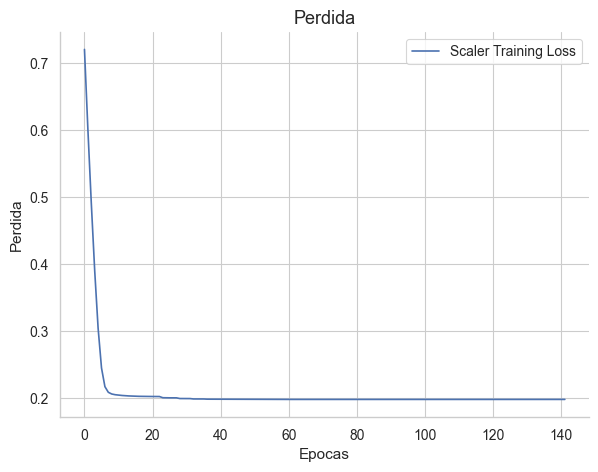

In [41]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Scaler Training Loss')
plt.title('Perdida')
plt.xlabel('Epocas')
plt.ylabel('Perdida')
plt.legend()

In [42]:
t_pred, t_logits, uncertainties = uq.predict_with_uncertainty(test)
t_pred = t_pred.numpy()
t_logits = t_logits.numpy()

In [43]:
#scaled_logits_samples = scaler(t_logits_samples)
#scaled_prob_samples = tf.nn.softmax(scaled_logits_samples, axis=-1)
#scaled_predictions = tf.reduce_mean(scaled_prob_samples, axis=1).numpy()
scaled_predictions = tf.nn.softmax(scaler(t_logits), axis=-1).numpy()

In [44]:
from sklearn.metrics import roc_auc_score
"""

Results of calibration evaluation metrics before and after scaling:










"""
def multiclass_nll(y_true, probs, eps=1e-15):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    probs = np.clip(probs, eps, 1.0)
    return -np.mean(np.log(probs[np.arange(y_true.size), y_true]))

def multiclass_brier_score(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    y_onehot = np.eye(probs.shape[1])[y_true]
    return np.mean(np.sum((y_onehot - probs) ** 2, axis=1))

def multiclass_auc_ovr_macro(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    y_onehot = np.eye(probs.shape[1])[y_true]
    return roc_auc_score(y_onehot, probs, average='macro', multi_class='ovr')

def calculate_ace_multiclass(probs, labels, n_bins=15):
    """ACE multiclase: promedio por clase, con bins adaptativos de igual tamano."""
    probs = np.asarray(probs, dtype=float)
    labels = np.asarray(labels, dtype=int)

    if probs.ndim != 2:
        raise ValueError('probs must have shape (n_samples, n_classes)')

    n_samples, n_classes = probs.shape
    if labels.size != n_samples:
        raise ValueError('labels and probs must contain the same number of samples')

    y_onehot = np.eye(n_classes)[labels]
    ace = 0.0

    for class_idx in range(n_classes):
        class_probs = probs[:, class_idx]
        class_truth = y_onehot[:, class_idx]

        order = np.argsort(class_probs, kind='mergesort')
        probs_sorted = class_probs[order]
        truth_sorted = class_truth[order]

        prob_bins = np.array_split(probs_sorted, n_bins)
        truth_bins = np.array_split(truth_sorted, n_bins)

        class_error = 0.0
        for prob_bin, truth_bin in zip(prob_bins, truth_bins):
            if prob_bin.size == 0:
                continue
            class_error += np.abs(np.mean(truth_bin) - np.mean(prob_bin))

        ace += class_error / n_bins

    return ace / n_classes

y_test_int = np.argmax(np.asarray(y_test), axis=1)

auc_values = []
nll_values = []
brier_values = []

for i in range(num_class):
    y_true = y_test[:, i]
    p = t_pred[:, i]
    p_scaled = scaled_predictions[:, i]

    auc_uncali = roc_auc_score(y_true, p)
    nll_score_uncali = -np.mean(
        y_true * np.log(np.clip(p, 1e-15, 1.0)) +
        (1 - y_true) * np.log(np.clip(1 - p, 1e-15, 1.0))
    )
    brier_uncali = np.mean((y_true - p) ** 2)

    auc_cali = roc_auc_score(y_true, p_scaled)
    nll_score_cali = -np.mean(
        y_true * np.log(np.clip(p_scaled, 1e-15, 1.0)) +
        (1 - y_true) * np.log(np.clip(1 - p_scaled, 1e-15, 1.0))
    )
    brier_cali = np.mean((y_true - p_scaled) ** 2)

    auc_values.append((auc_uncali, auc_cali))
    nll_values.append((nll_score_uncali, nll_score_cali))
    brier_values.append((brier_uncali, brier_cali))


In [45]:
from IPython.display import display

results = pd.DataFrame([], columns=['Class', 'AUC Uncalibrated', 'AUC Calibrated', 'NLL Uncalibrated', 'NLL Calibrated', 'Brier Uncalibrated', 'Brier Calibrated'])
for i in range(num_class):
    results.loc[len(results)] = {
        'Class': i + 1,
        'AUC Uncalibrated': auc_values[i][0],
        'AUC Calibrated': auc_values[i][1],
        'NLL Uncalibrated': nll_values[i][0],
        'NLL Calibrated': nll_values[i][1],
        'Brier Uncalibrated': brier_values[i][0],
        'Brier Calibrated': brier_values[i][1]
    }

summary_results = pd.DataFrame([
    {
        'Metric': 'NLL (multiclase)',
        'Before Calibration': multiclass_nll(y_test_int, t_pred),
        'After Calibration': multiclass_nll(y_test_int, scaled_predictions),
    },
    {
        'Metric': 'ACE (multiclase)',
        'Before Calibration': calculate_ace_multiclass(t_pred, y_test_int, n_bins=15),
        'After Calibration': calculate_ace_multiclass(scaled_predictions, y_test_int, n_bins=15),
    },
    {
        'Metric': 'AUC-ROC macro (OVR)',
        'Before Calibration': multiclass_auc_ovr_macro(y_test_int, t_pred),
        'After Calibration': multiclass_auc_ovr_macro(y_test_int, scaled_predictions),
    },
    {
        'Metric': 'Brier score (multiclase)',
        'Before Calibration': multiclass_brier_score(y_test_int, t_pred),
        'After Calibration': multiclass_brier_score(y_test_int, scaled_predictions),
    },
])

display(
    results.style.format({
        'AUC Uncalibrated': '{:.4f}',
        'AUC Calibrated': '{:.4f}',
        'NLL Uncalibrated': '{:.4f}',
        'NLL Calibrated': '{:.4f}',
        'Brier Uncalibrated': '{:.4f}',
        'Brier Calibrated': '{:.4f}',
    }).highlight_min(
        subset=['NLL Uncalibrated', 'NLL Calibrated', 'Brier Uncalibrated', 'Brier Calibrated'],
        color='lightgreen'
    )
)

display(
    summary_results.style.format({
        'Before Calibration': '{:.4f}',
        'After Calibration': '{:.4f}',
    }).highlight_min(
        subset=['Before Calibration', 'After Calibration'],
        color='lightgreen'
    )
)


,Class,AUC Uncalibrated,AUC Calibrated,NLL Uncalibrated,NLL Calibrated,Brier Uncalibrated,Brier Calibrated
0,1,0.9916,0.9906,0.0705,0.0586,0.0146,0.0141
1,2,0.9931,0.9934,0.1129,0.0944,0.0261,0.0242
2,3,0.9936,0.9934,0.0775,0.0719,0.0197,0.0189
3,4,0.9922,0.9933,0.0579,0.0447,0.0113,0.0106
4,5,0.9935,0.9939,0.0370,0.0266,0.0066,0.0060
5,6,0.9975,0.9976,0.0325,0.0230,0.0055,0.0051
6,7,0.9988,0.9991,0.0110,0.0081,0.0017,0.0017


,Metric,Before Calibration,After Calibration
0,NLL (multiclase),0.2515,0.1934
1,ACE (multiclase),0.0093,0.0031
2,AUC-ROC macro (OVR),0.9943,0.9945
3,Brier score (multiclase),0.0855,0.0805


In [46]:
from sklearn.metrics import brier_score_loss, roc_auc_score

def nll(y_true, p, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)
    
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if np.sum(mask) > 0:
            bin_prob_true = np.mean(y_true[mask])
            bin_prob_pred = np.mean(p[mask])
            bin_weight = np.sum(mask) / len(p)
            ece += bin_weight * np.abs(bin_prob_true - bin_prob_pred)
    
    return ece

In [22]:
from sklearn.calibration import calibration_curve
from scipy import stats
from matplotlib.gridspec import GridSpec

def plot_reliability_diagram(
    y_true, y_pred,
    title="Reliability Diagram",
    n_bins=10,
    show_histogram=True,
    show_density=True,
    figsize=(12, 8),
    color='steelblue',
    calibration_color='darkorange',
    alpha=0.8
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    quantiles = np.linspace(0.0, 1.0, n_bins + 1)
    bin_edges = np.percentile(y_pred, quantiles * 100)

    bin_ids = np.digitize(y_pred, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    prob_true = np.zeros(n_bins)
    prob_pred = np.zeros(n_bins)
    bin_counts = np.zeros(n_bins)

    for b in range(n_bins):
        mask = bin_ids == b
        bin_counts[b] = np.sum(mask)

        if bin_counts[b] > 0:
            prob_true[b] = np.mean(y_true[mask])
            prob_pred[b] = np.mean(y_pred[mask])
        else:
            prob_true[b] = np.nan
            prob_pred[b] = np.nan

    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred)
    n_l_l = nll(y_true, y_pred)

    if show_histogram:
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(2, 2, height_ratios=[3, 1], width_ratios=[3, 1])
        ax = fig.add_subplot(gs[0, 0])
        ax_histx = fig.add_subplot(gs[1, 0], sharex=ax)
        ax_histy = fig.add_subplot(gs[0, 1], sharey=ax)
    else:
        fig, ax = plt.subplots(figsize=figsize)
        ax_histx = ax_histy = None

    ax.plot([0, 1], [0, 1], "k--", lw=2, label="Calibración perfecta")

    # Curva de calibración
    ax.plot(
        prob_pred, prob_true,
        marker='s',
        color=calibration_color,
        linewidth=3,
        markersize=8,
        markerfacecolor='white',
        markeredgewidth=2,
        label="Curva de calibración"
    )

    if show_density and np.sum(y_true == 1) > 5:
        kde = stats.gaussian_kde(y_pred[y_true == 1])
        x = np.linspace(0, 1, 300)
        y = kde(x)
        y = y / y.max() * 0.3
        ax.fill_between(x, 0, y, color='green', alpha=0.2,
                        label="Densidad (clase positiva)")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Probabilidades producidas", fontweight='bold')
    ax.set_ylabel("Fracción de positivos", fontweight='bold')
    ax.set_title(title, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

    text = (
        f"Brier: {brier:.6f}\n"
        f"NLL: {n_l_l:.6f}\n"
        f"ECE: {ece:.6f}\n"
        f"Positives: {int(y_true.sum())}/{len(y_true)}"
    )
    ax.text(0.02, 0.98, text, transform=ax.transAxes,
            va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    ax.legend(loc='lower right')

    if show_histogram:
        ax_histx.hist(y_pred, bins=quantiles, color=color,
                      alpha=alpha, edgecolor='black')
        ax_histx.set_ylabel("Count")
        ax_histx.grid(True, alpha=0.3)

        ax_histy.hist(y_true, bins=2, orientation='horizontal',
                      color='gray', alpha=0.7, edgecolor='black')
        ax_histy.set_xlabel("Count")
        ax_histy.grid(True, alpha=0.3)

    plt.tight_layout()


    return fig


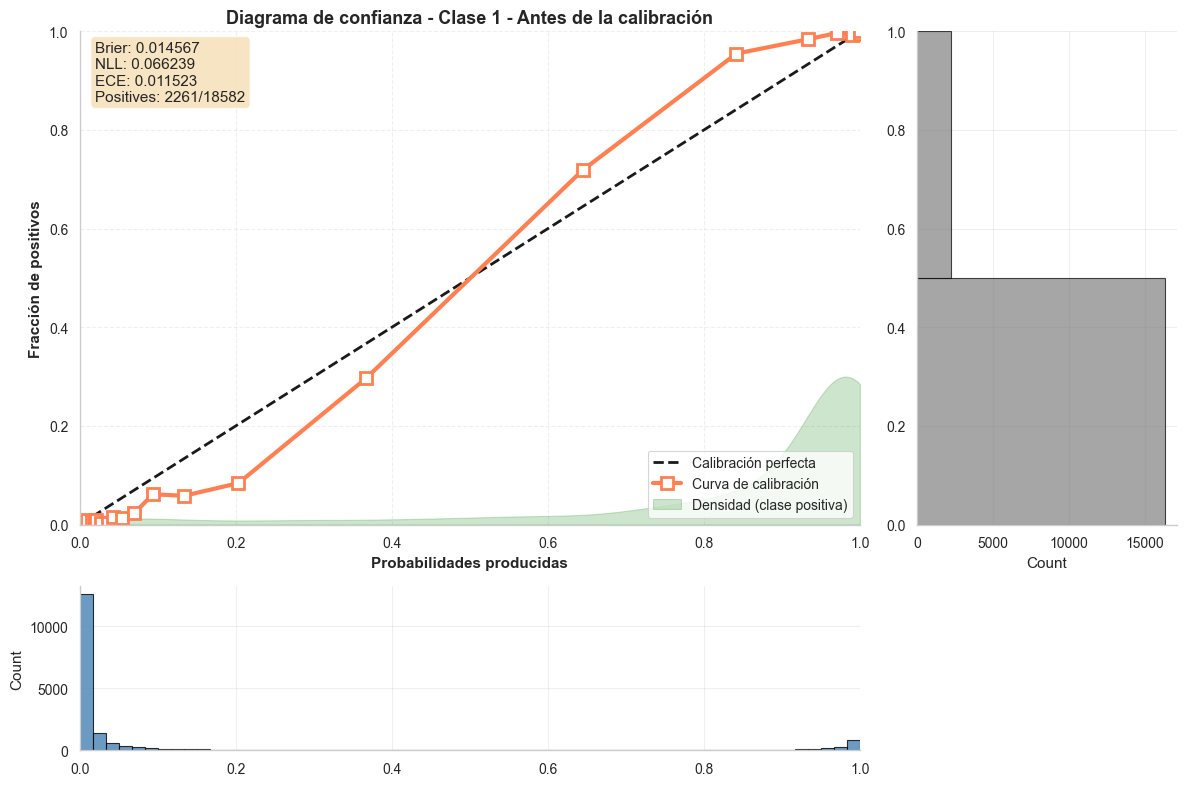

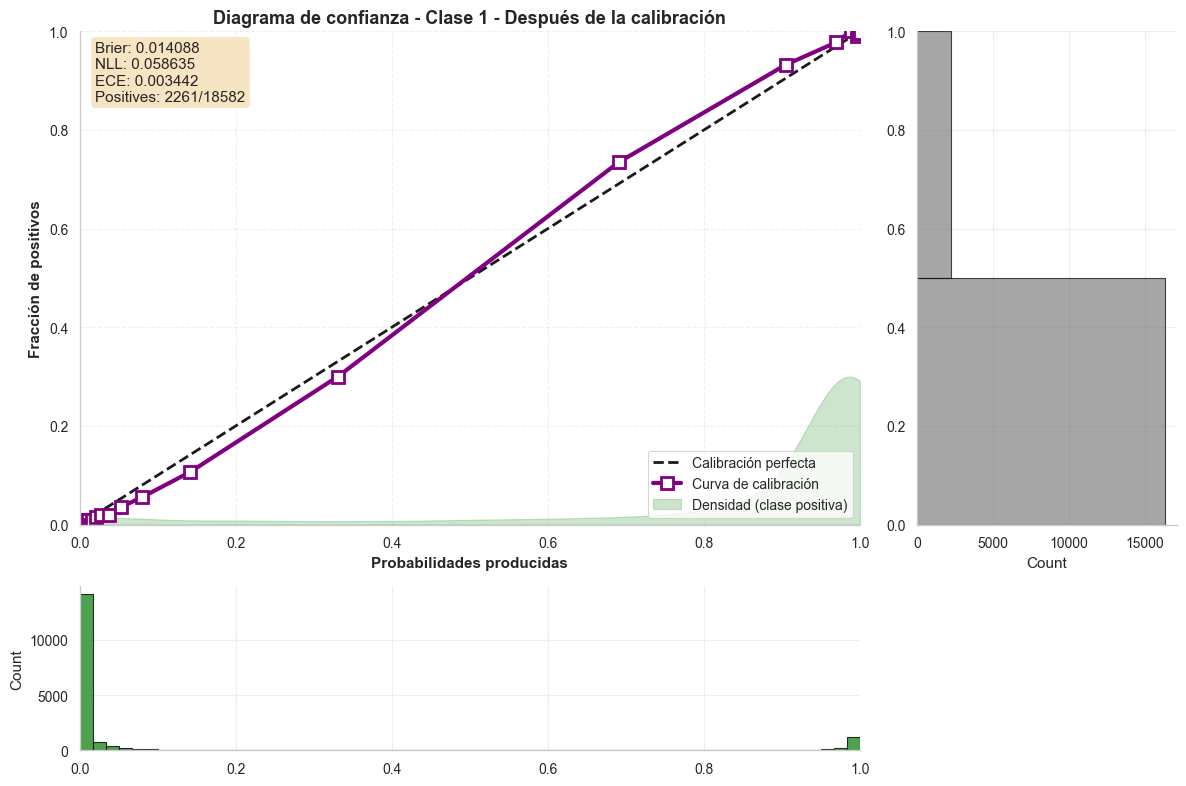

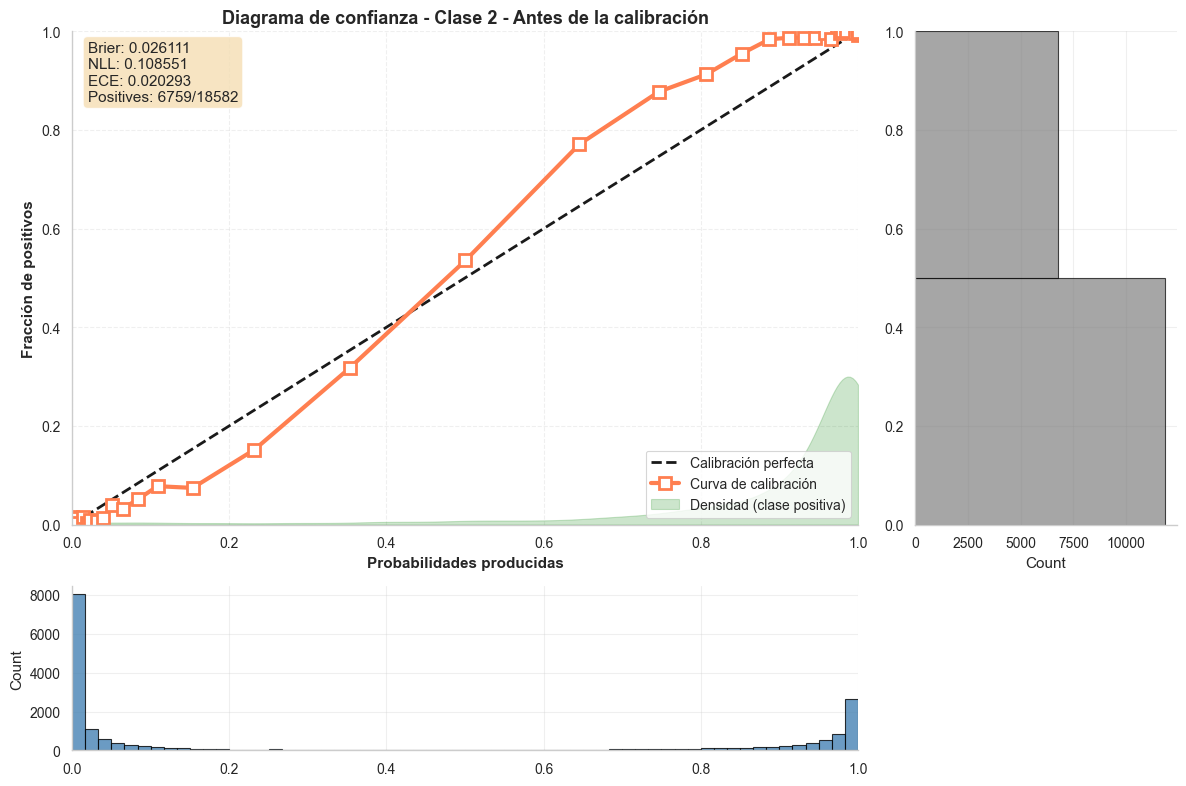

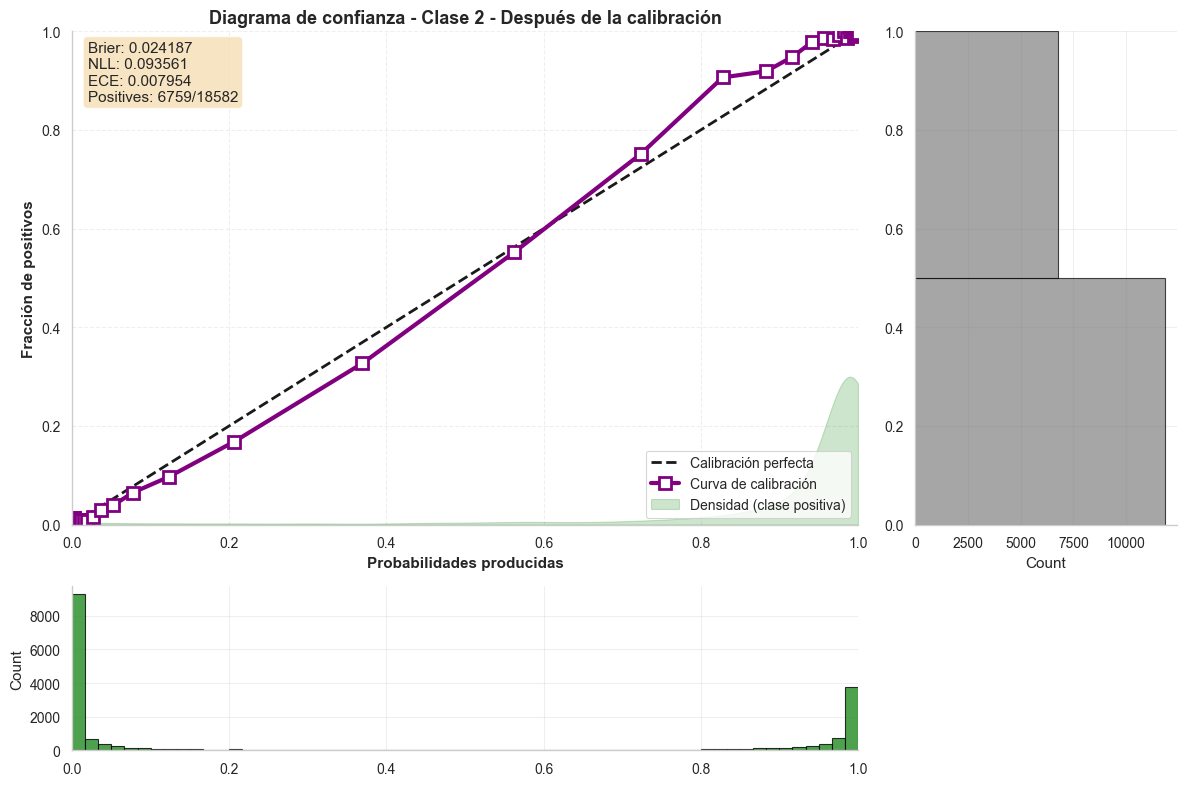

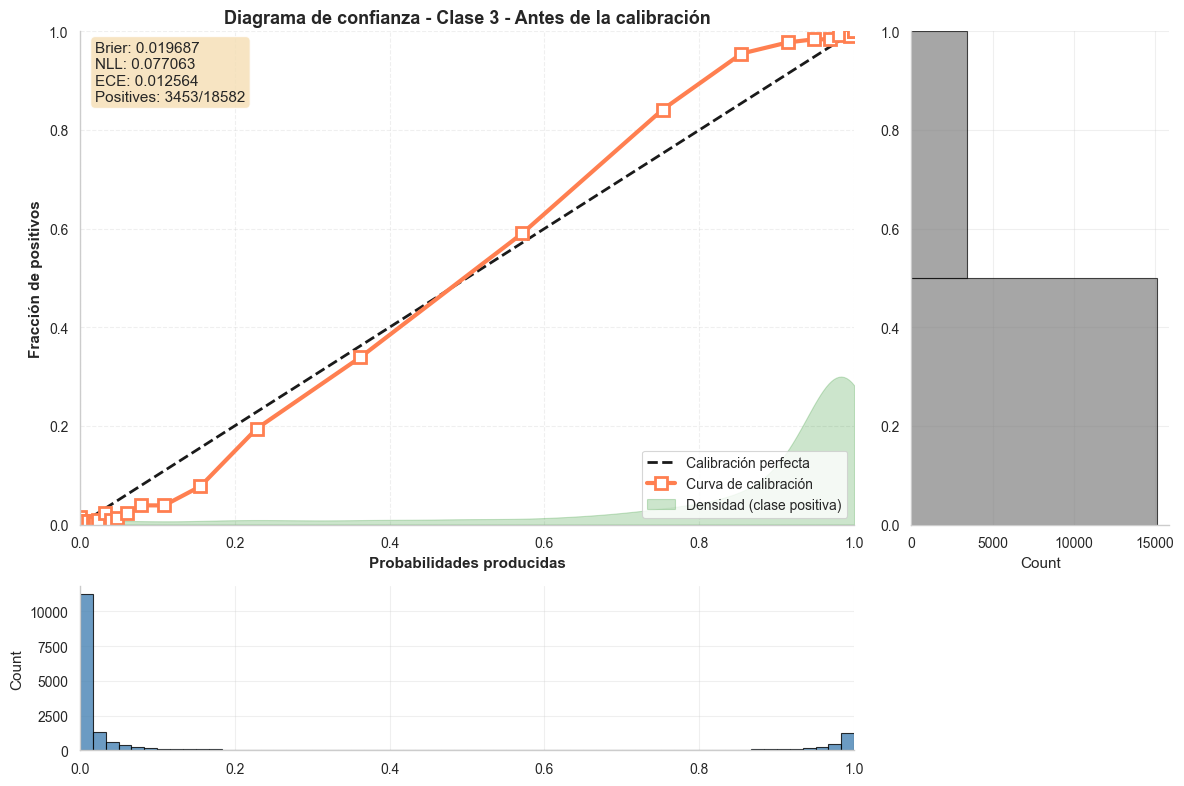

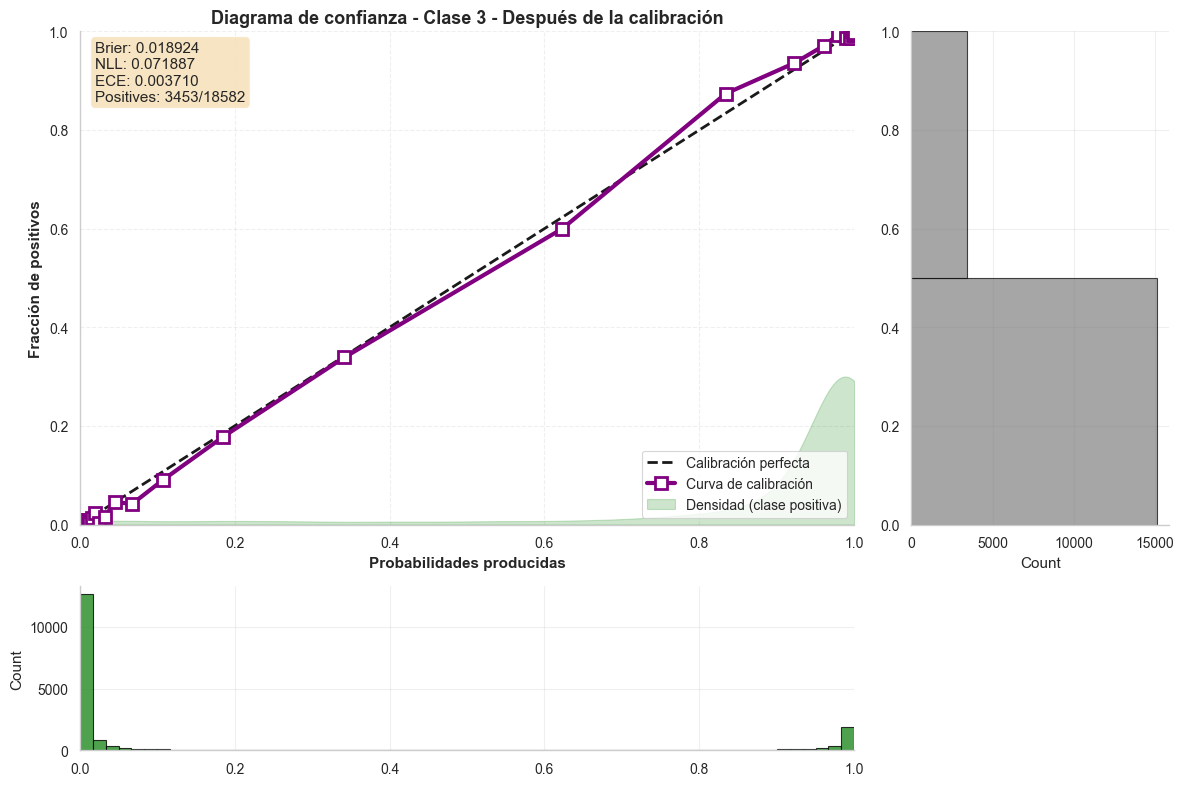

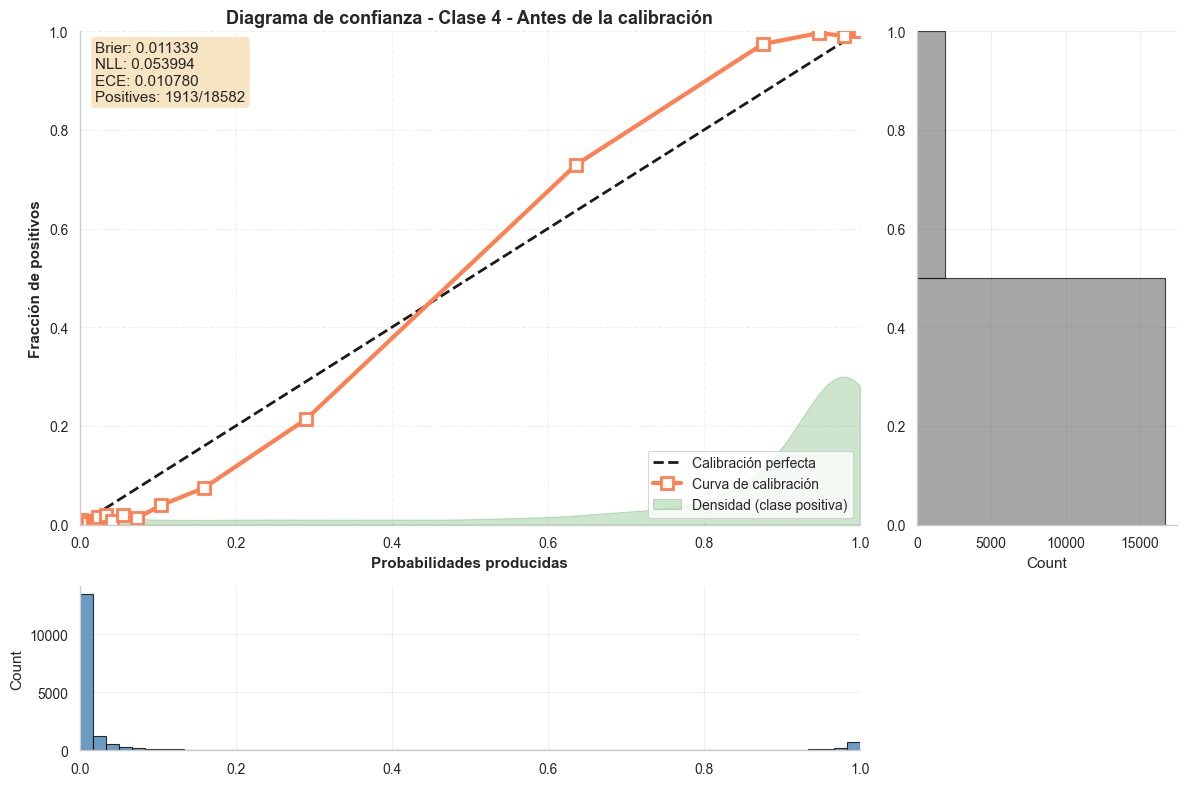

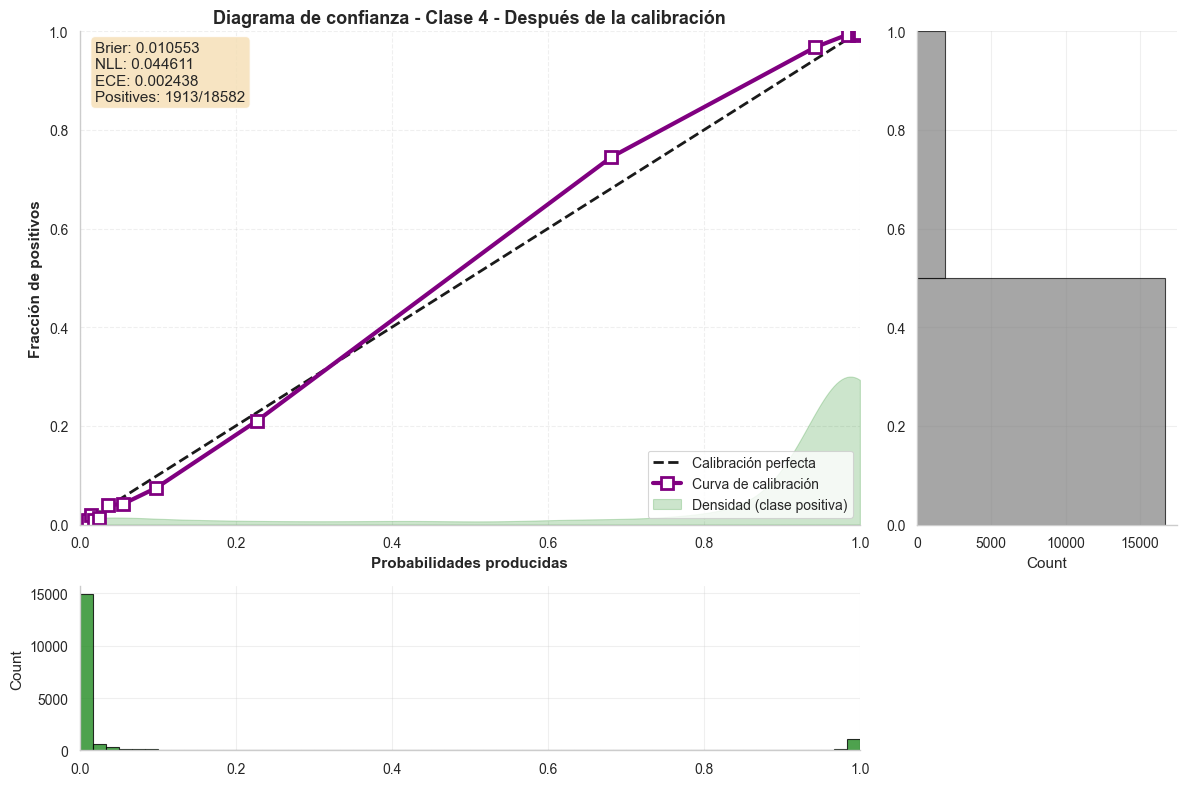

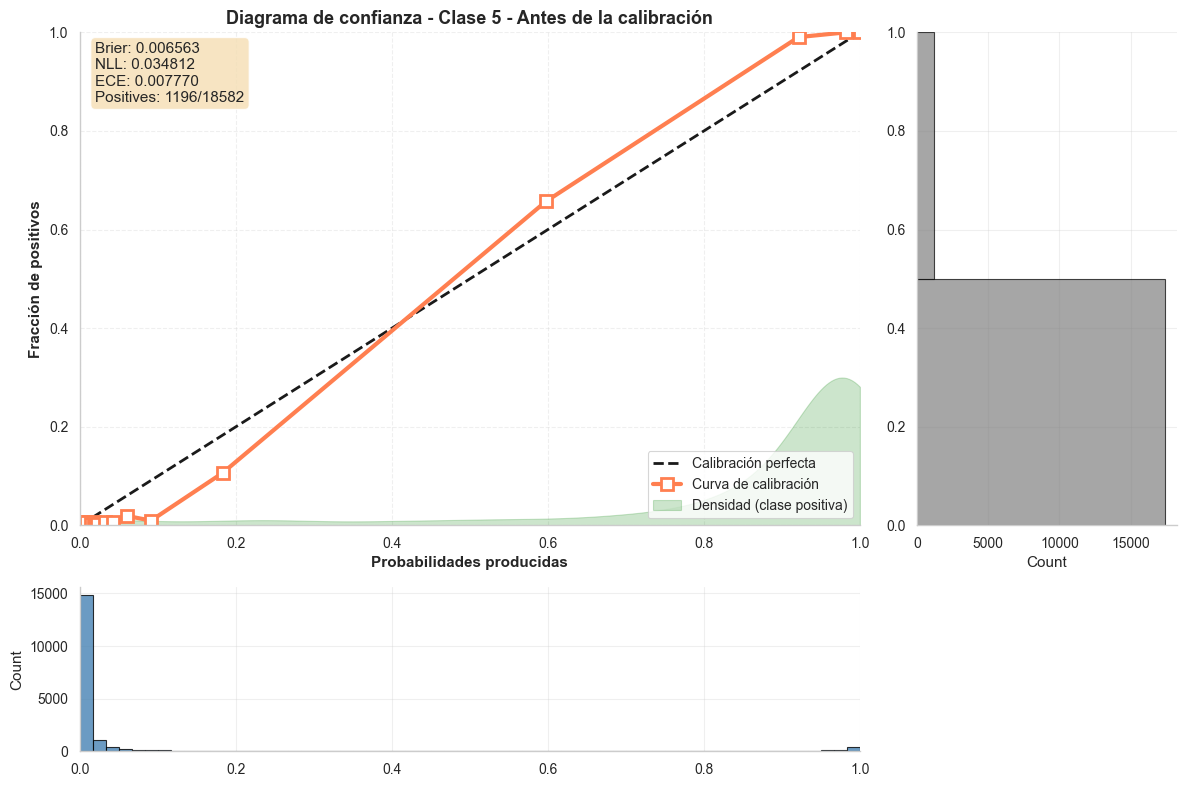

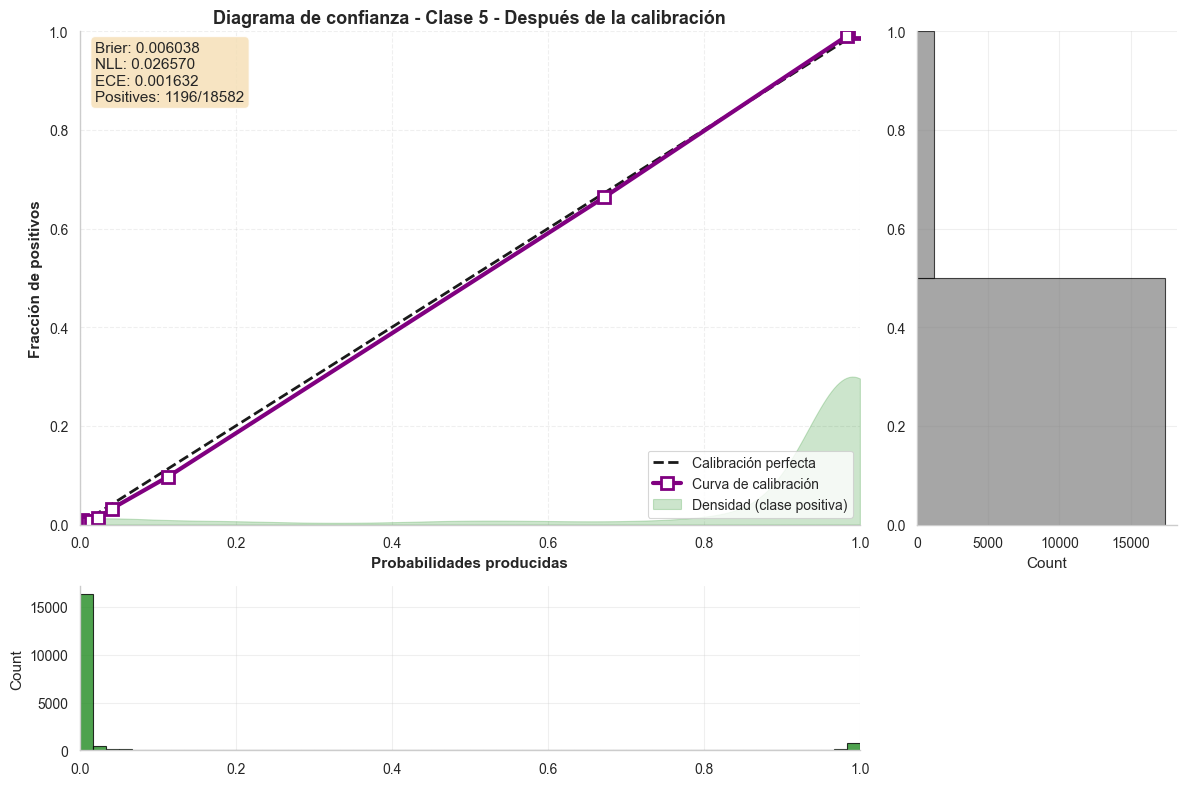

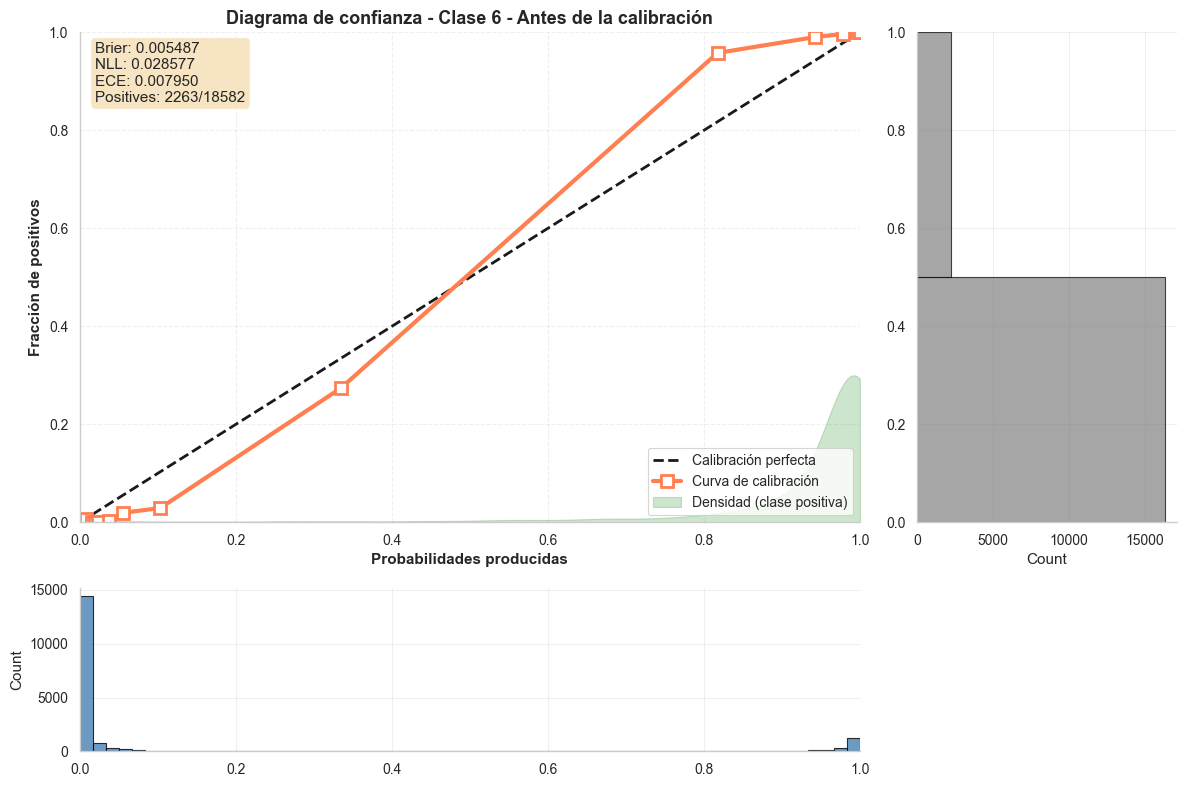

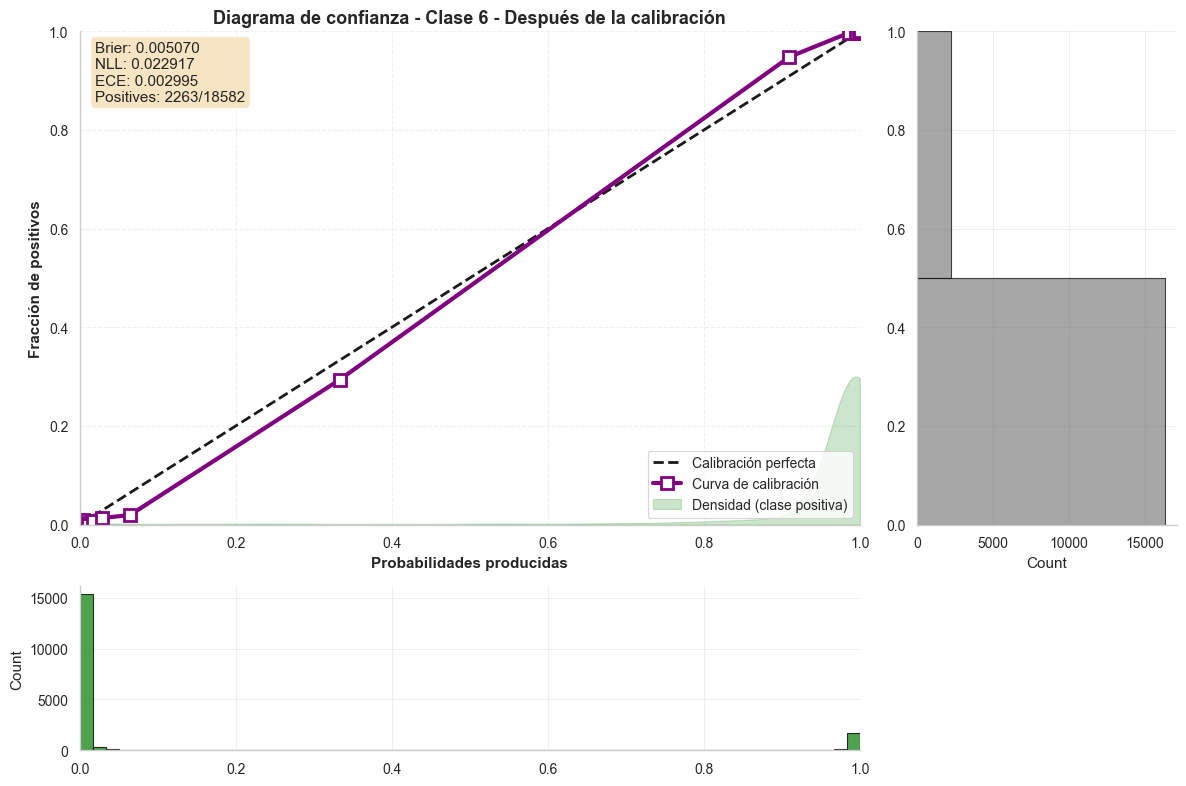

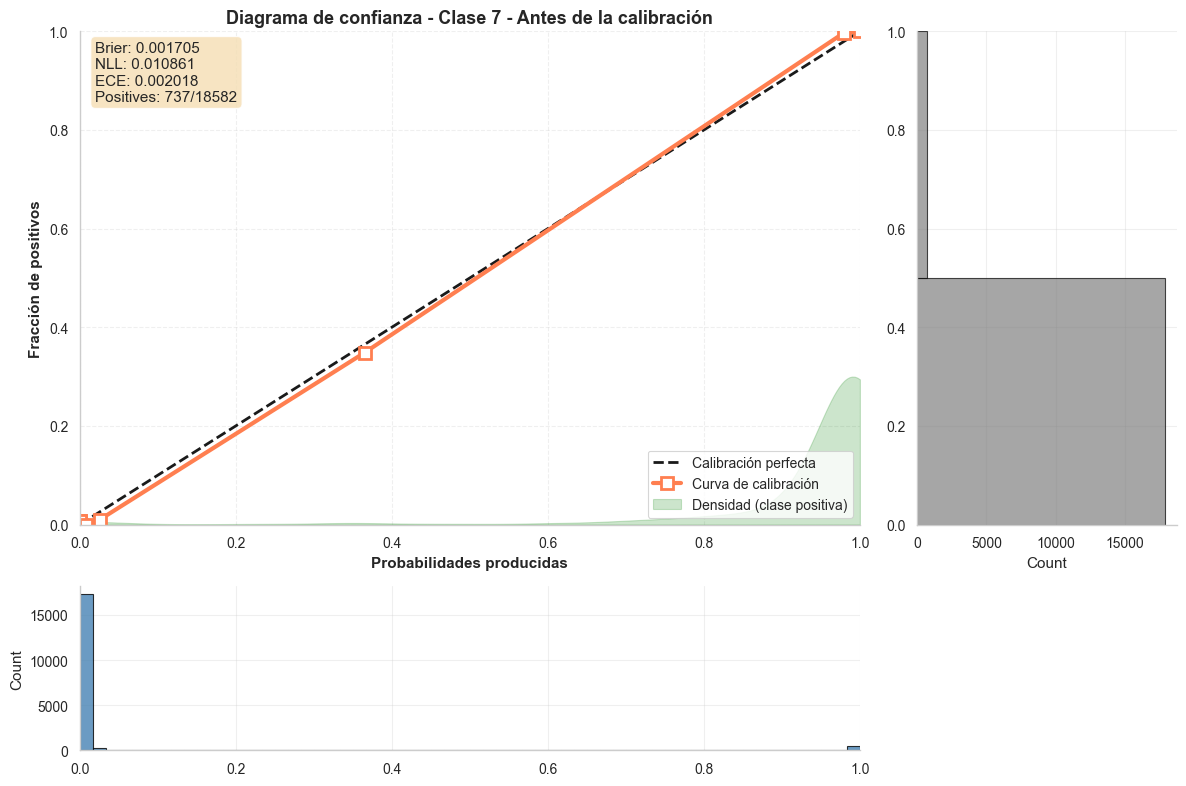

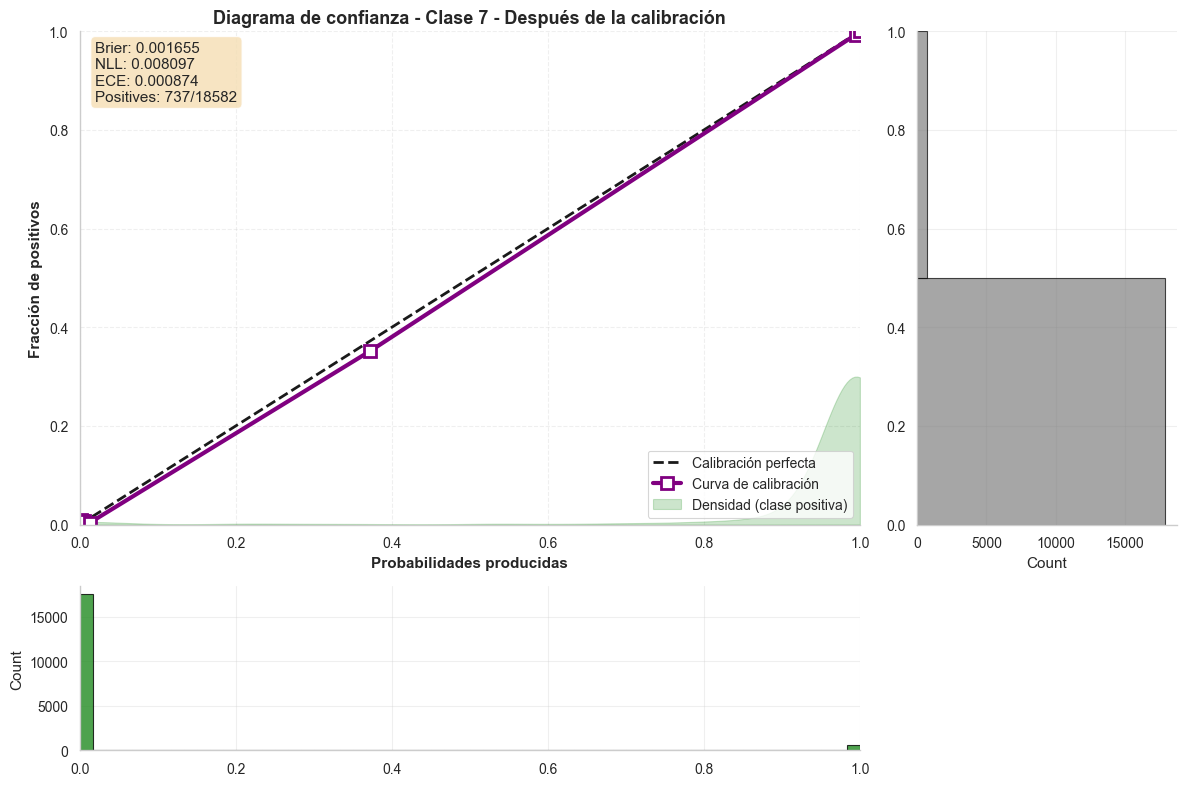

In [23]:
for i in range(num_class):
    plot_reliability_diagram(
        y_true=y_test[:, i],
        y_pred=t_pred[:, i],
        title=f"Diagrama de confianza - Clase {i + 1} - Antes de la calibración",
        n_bins=60,
        show_histogram=True,
        show_density=True,
        color='steelblue',
        calibration_color='coral'
    )
    plot_reliability_diagram(
        y_true=y_test[:, i],
        y_pred=scaled_predictions[:, i],
        title=f"Diagrama de confianza - Clase {i + 1} - Después de la calibración",
        n_bins=60,
        show_histogram=True,
        show_density=True,
        color='forestgreen',
        calibration_color='purple'
    )

In [47]:
def plot_confidence_histogram(y_true, y_pred_prob_positive, y_pred_labels=None, 
                                        threshold=0.5, n_bins=10, model_name="Modelo"):
    """
    Histograma de confianza CORREGIDO: usa la confianza en la predicción realizada
    
    Parámetros:
    -----------
    y_true : array
        Etiquetas verdaderas (0 o 1)
    y_pred_prob_positive : array
        Probabilidades predichas para la clase positiva
    y_pred_labels : array, opcional
        Etiquetas predichas (si None, se calculan con threshold)
    n_bins : int
        Nú mero de intervalos para el histograma (0.5-1.0)
    threshold : float
        Umbral para clasificación
    model_name : str
        Nombre del modelo para el tí tulo
    """
    
    y_true = np.asarray(y_true)
    y_pred_prob_positive = np.asarray(y_pred_prob_positive)
    is_multiclass = y_pred_prob_positive.ndim == 2
    
    if y_true.ndim > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.astype(int)
    
    if is_multiclass:
        if y_pred_labels is None:
            y_pred_labels = np.argmax(y_pred_prob_positive, axis=1)
        else:
            y_pred_labels = np.asarray(y_pred_labels)
            if y_pred_labels.ndim > 1:
                y_pred_labels = np.argmax(y_pred_labels, axis=1)
            y_pred_labels = y_pred_labels.astype(int)
        confidence = np.max(y_pred_prob_positive, axis=1)
        bins = np.linspace(0.0, 1.0, n_bins + 1)
    else:
        if y_pred_labels is None:
            y_pred_labels = (y_pred_prob_positive >= threshold).astype(int)
        else:
            y_pred_labels = np.asarray(y_pred_labels).astype(int)
        y_pred_prob_negative = 1 - y_pred_prob_positive
        confidence = np.where(y_pred_labels == 1, 
                              y_pred_prob_positive,  # Si predice clase 1, confianza = P(clase=1)
                              y_pred_prob_negative)  # Si predice clase 0, confianza = P(clase=0)
        bins = np.linspace(0.5, 1.0, n_bins + 1)
    
    # 2. IDENTIFICAR PREDICCIONES CORRECTAS/INCORRECTAS
    correct = (y_pred_labels == y_true_labels)
    incorrect = ~correct
    
    # 3. CREAR BINS SOLO PARA CONFIANZA
    bin_centers = (bins[:-1] + bins[1:]) / 2
    width = (bins[1] - bins[0]) * 0.38
    
    # 4. CALCULAR DISTRIBUCIÓN
    conf_correct = confidence[correct]
    conf_incorrect = confidence[incorrect]
    
    counts_correct, _ = np.histogram(conf_correct, bins=bins)
    counts_incorrect, _ = np.histogram(conf_incorrect, bins=bins)
    total_counts = counts_correct + counts_incorrect
    
    error_rate_by_bin = []
    n_samples_by_bin = []
    
    for i in range(n_bins):
        mask = (confidence >= bins[i]) & (confidence < bins[i+1])
        if i == n_bins - 1:
            mask = (confidence >= bins[i]) & (confidence <= bins[i+1])
        
        n_samples = np.sum(mask)
        n_samples_by_bin.append(n_samples)
        
        if n_samples > 0:
            error_rate = np.sum(y_pred_labels[mask] != y_true_labels[mask]) / n_samples
            error_rate_by_bin.append(error_rate)
        else:
            error_rate_by_bin.append(0)
    
    total_samples = len(y_true_labels)
    
    if is_multiclass:
        AUC_ROC = multiclass_auc_ovr_macro(y_true_labels, y_pred_prob_positive)
        brier_score = multiclass_brier_score(y_true_labels, y_pred_prob_positive)
    else:
        AUC_ROC = roc_auc_score(y_true_labels, y_pred_prob_positive)
        brier_score = brier_score_loss(y_true_labels, y_pred_prob_positive)
    
    # Confianza promedio por tipo de predicción
    avg_conf_all = np.mean(confidence) if total_samples > 0 else 0
    avg_conf_correct = np.mean(confidence[correct]) if np.sum(correct) > 0 else 0
    avg_conf_incorrect = np.mean(confidence[incorrect]) if np.sum(incorrect) > 0 else 0
    
    # Expected Calibration Error (ECE) sobre la confianza real de la predicción
    def _confidence_ece(confidence_values, correct_mask, n_bins_local):
        bin_edges = np.linspace(0.0, 1.0, n_bins_local + 1)
        bin_ids = np.digitize(confidence_values, bin_edges, right=True) - 1
        bin_ids = np.clip(bin_ids, 0, n_bins_local - 1)
        ece_value = 0.0
        for b in range(n_bins_local):
            mask = bin_ids == b
            if np.sum(mask) > 0:
                bin_acc = np.mean(correct_mask[mask])
                bin_conf = np.mean(confidence_values[mask])
                ece_value += (np.sum(mask) / len(confidence_values)) * abs(bin_acc - bin_conf)
        return ece_value
    
    ece = _confidence_ece(confidence, correct, n_bins)
    
    # Tasa de error en alta confianza (> 0.9)
    high_conf_mask = confidence >= 0.9
    n_high_conf = np.sum(high_conf_mask)
    if n_high_conf > 0:
        high_conf_error_rate = np.sum(y_pred_labels[high_conf_mask] != 
                                     y_true_labels[high_conf_mask]) / n_high_conf
    else:
        high_conf_error_rate = 0
    
    # Distribución de confianza
    low_conf = np.sum(confidence < 0.6) / total_samples if total_samples > 0 else 0
    medium_conf = np.sum((confidence >= 0.6) & (confidence < 0.8)) / total_samples if total_samples > 0 else 0
    high_conf = np.sum(confidence >= 0.8) / total_samples if total_samples > 0 else 0
    
    # Cálculo de métricas clave
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'Histograma de Confianza - {model_name}', 
                 fontsize=16, fontweight='bold')
    
    # SUBPLOT 1: HISTOGRAMA DE CONFIANZA
    ax1 = axes[0, 0]
    
    # Barras para correctas e incorrectas
    ax1.bar(bin_centers - width/2, counts_correct, width=width, 
            alpha=0.7, label='Correctas', color='#2ecc71', edgecolor='black', linewidth=0.5)
    ax1.bar(bin_centers + width/2, counts_incorrect, width=width, 
            alpha=0.7, label='Incorrectas', color='#e74c3c', edgecolor='black', linewidth=0.5)
    
    ax1.set_xlabel('Confianza del Modelo (max(P(clase)))', fontsize=12)
    ax1.set_ylabel('Número de Muestras', fontsize=12)
    ax1.set_title('Distribución de Confianza por Exactitud de Predicción', fontsize=14)
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_xlim(bins[0], bins[-1])
    
    # Añadir porcentaje de correctas por bin
    for i, (corr, incorr) in enumerate(zip(counts_correct, counts_incorrect)):
        total = corr + incorr
        if total > 0:
            percentage = corr / total
            ax1.text(bin_centers[i], max(corr, incorr) + max(total_counts)*0.02, 
                    f'{percentage:.0%}', ha='center', fontsize=9, 
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
    
    # Línea vertical en 0.5 para referencia
    ax1.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)
    
    # SUBPLOT 2: TASA DE ERROR POR NIVEL DE CONFIANZA
    ax2 = axes[0, 1]
    
    # Gráfico de barras para tasa de error
    bars = ax2.bar(bin_centers, error_rate_by_bin, width=width*2,
                   color=['#e74c3c' if rate > 0.5 else 
                         '#f39c12' if rate > 0.2 else 
                         '#2ecc71' for rate in error_rate_by_bin],
                   edgecolor='black', linewidth=1)
    
    # Resaltar bins problemáticos
    for i, (err_rate, n_samples) in enumerate(zip(error_rate_by_bin, n_samples_by_bin)):
        if err_rate > 0.5 and bins[i] > 0.8:  # Alta confianza pero error alto
            bars[i].set_hatch('//')
            bars[i].set_linewidth(2)
            ax2.text(bin_centers[i], err_rate + 0.03, "⚠ PELIGRO", 
                    ha='center', fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.8))
        
        # Mostrar número de muestras
        if n_samples > 0:
            ax2.text(bin_centers[i], err_rate/2, f'n={n_samples}', 
                    ha='center', fontsize=8, color='white', fontweight='bold')
    
    ax2.set_xlabel('Intervalo de Confianza', fontsize=12)
    ax2.set_ylabel('Tasa de Error', fontsize=12)
    ax2.set_title('Tasa de Error por Nivel de Confianza', fontsize=14)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, 1)
    
    # SUBPLOT 4: MÉTRICAS DE RESUMEN
    ax3 = axes[1, 0]
    ax3.axis('off')
    ax4 = axes[1, 1]
    ax4.axis('off')
    
    # Texto con métricas
    metrics_text = (
        f'RESUMEN DEL MODELO - CONFIANZA CORREGIDA\n{"="*45}\n\n'
        f'• AUC-ROC Score: {AUC_ROC:.2%}\n'
        f'• Brier Score: {brier_score:.4f}\n'
        f'• Expected Calibration Error (ECE): {ece:.4f}\n\n'
        
        f'CONFIANZA PROMEDIO\n{"="*20}\n'
        f'• Todas las muestras: {avg_conf_all:.3f}\n'
        f'• Predicciones CORRECTAS: {avg_conf_correct:.3f}\n'
        f'• Predicciones INCORRECTAS: {avg_conf_incorrect:.3f}\n'
        f'• Diferencia: {avg_conf_correct - avg_conf_incorrect:.3f}\n\n'
        
        f'DISTRIBUCIÓN DE CONFIANZA\n{"="*25}\n'
        f'• Baja (<0.6): {low_conf:.1%}\n'
        f'• Media (0.6-0.8): {medium_conf:.1%}\n'
        f'• Alta (>0.8): {high_conf:.1%}\n\n'
        
        f'ANÁLISIS DE RIESGO\n{"="*20}\n'
        f'• Error en alta confianza (>0.9): {high_conf_error_rate:.2%}\n'
        f'• Muestras de alta confianza: {n_high_conf} ({n_high_conf/total_samples:.1%})\n'
        f'• Máximo error tolerable: <5%\n'
    )
    
    # Añadir evaluación de calibración
    if ece < 0.01:
        cal_grade = "★ EXCELENTE ★"
        cal_color = "green"
    elif ece < 0.05:
        cal_grade = "✓ BUENO"
        cal_color = "orange"
    elif ece < 0.1:
        cal_grade = "⚠ ACEPTABLE"
        cal_color = "darkorange"
    else:
        cal_grade = "✗ REQUIERE RECALIBRACIÓN"
        cal_color = "red"
    
    cal_text = f'\nEVALUACIÓN DE CALIBRACIÓN\n{"="*25}\n{cal_grade}\nECE: {ece:.4f}'
    
    ax3.text(0.05, 0.95, metrics_text, transform=ax3.transAxes, 
             fontsize=10, verticalalignment='top', fontfamily='monospace')
    """
    ax3.text(0.05, 0.25, cal_text, transform=ax3.transAxes,
             fontsize=11, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgray', 
                     edgecolor=cal_color, linewidth=2))
    """
    
    plt.tight_layout()
    plt.show()


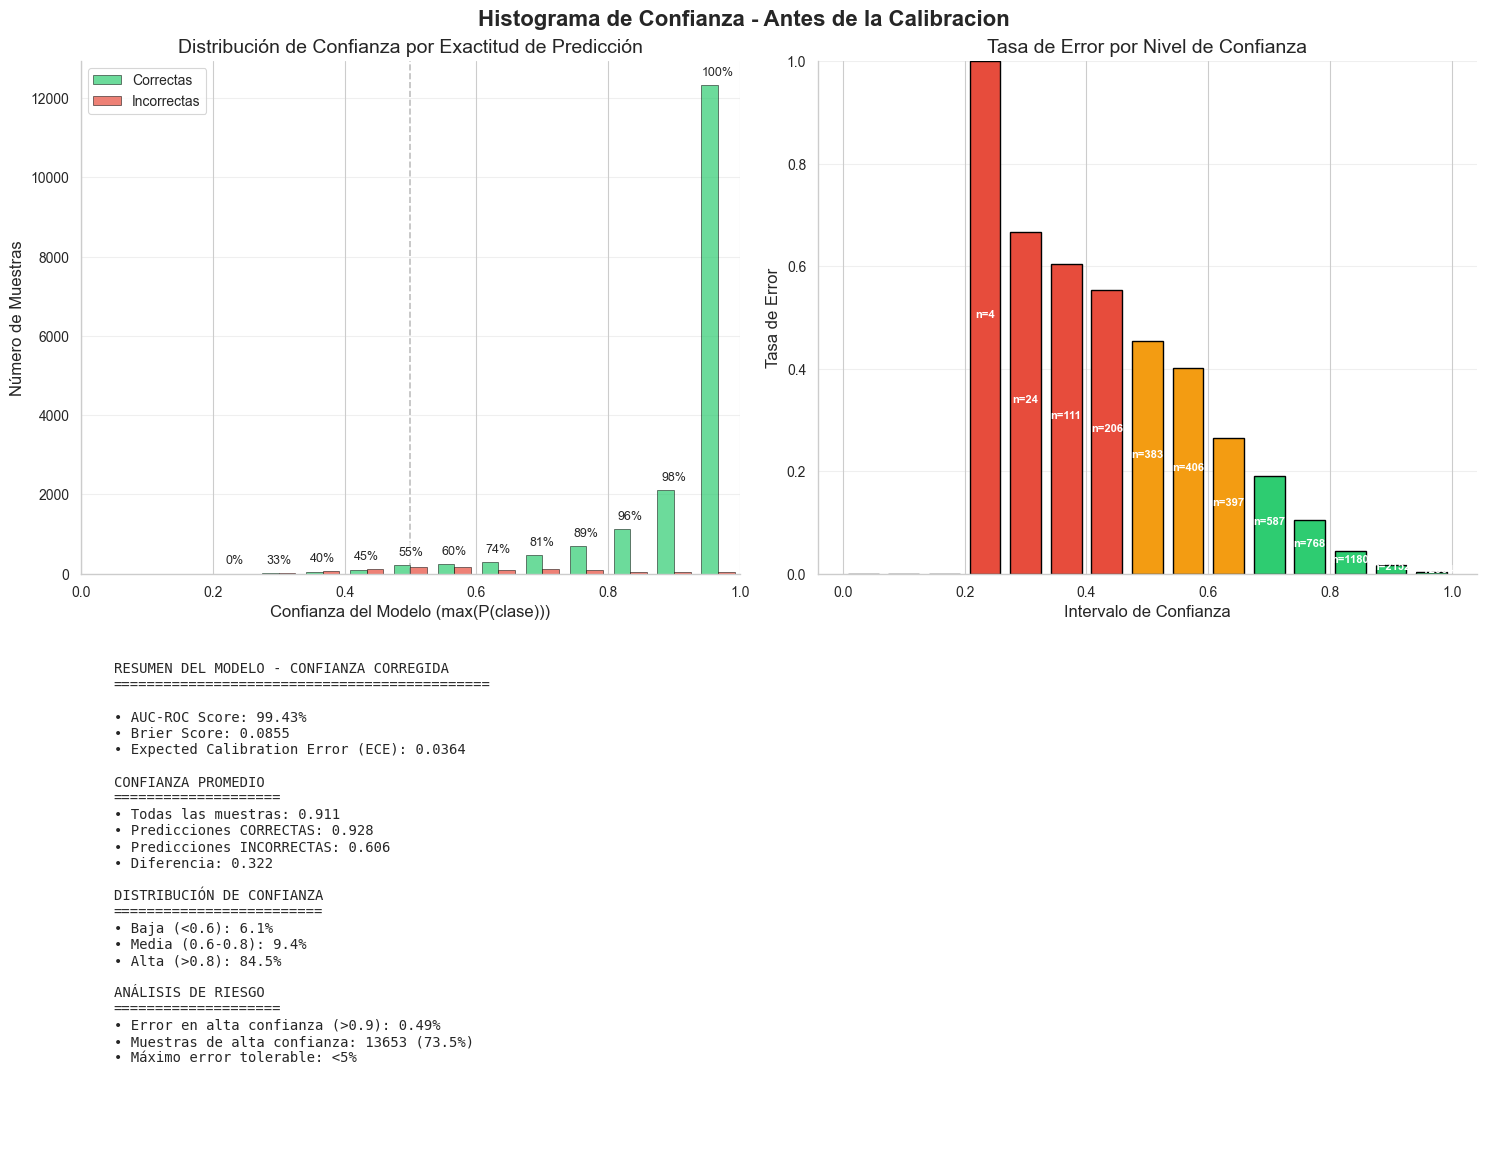

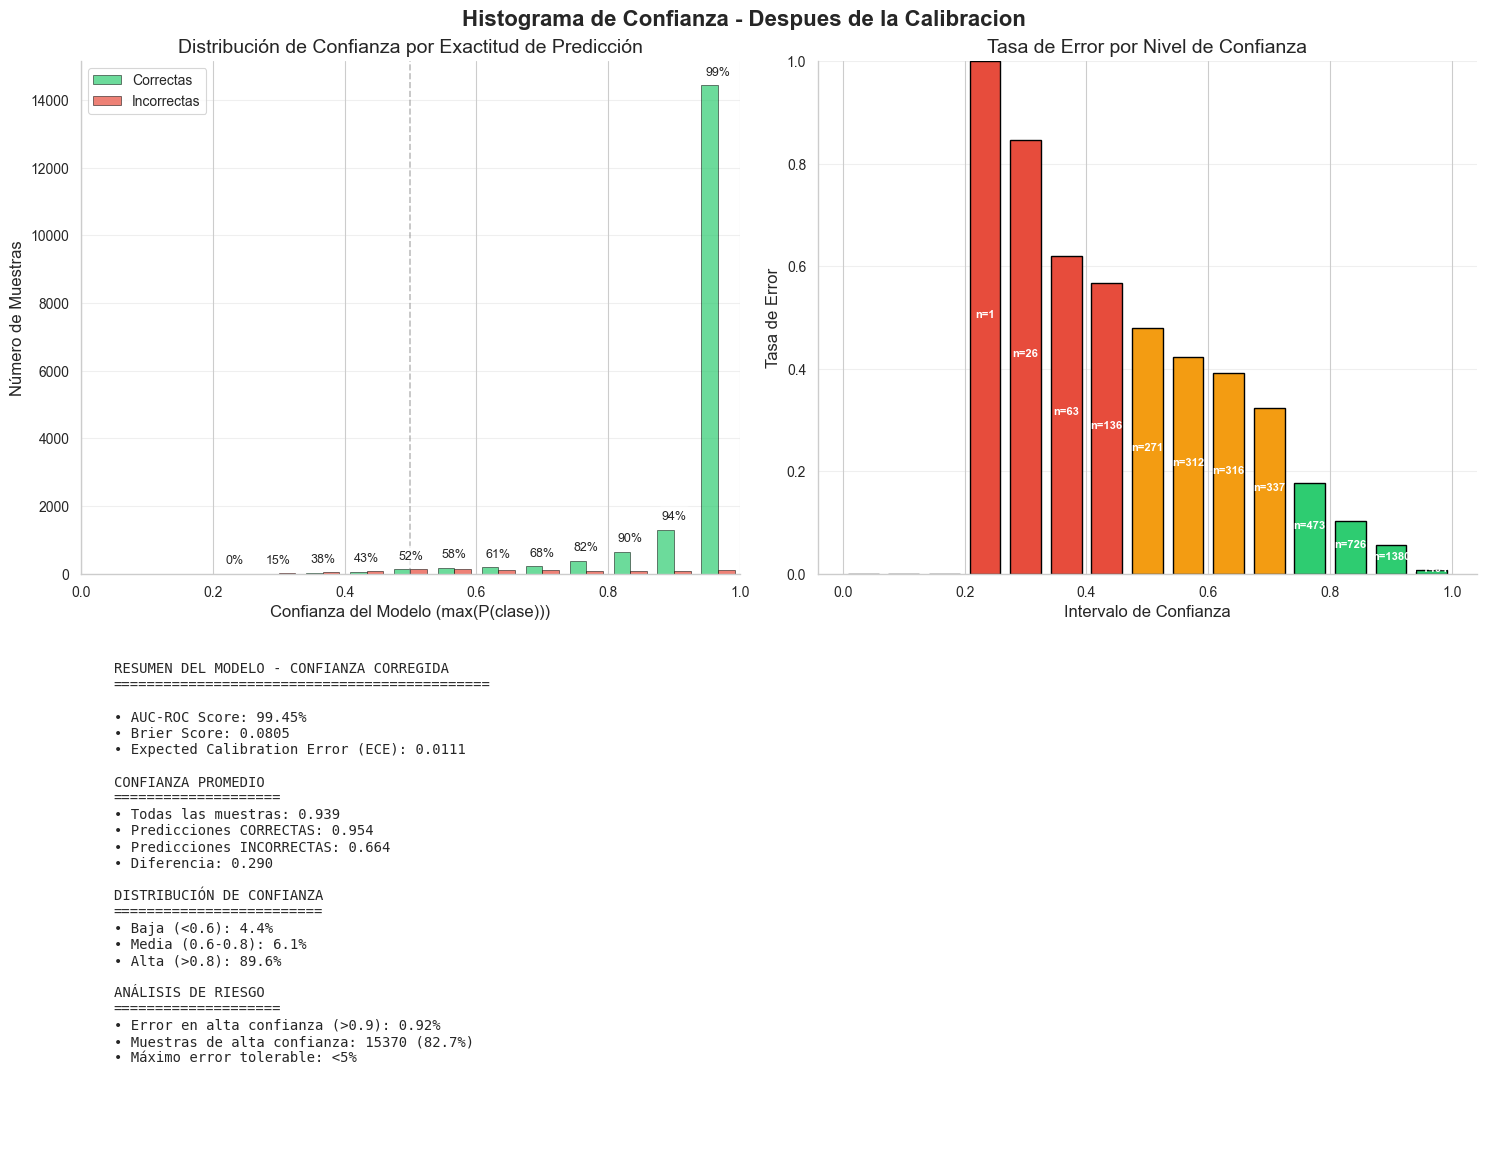

In [48]:
plot_confidence_histogram(y_test, t_pred, n_bins=15, model_name="Antes de la Calibracion")
plot_confidence_histogram(y_test, scaled_predictions, n_bins=15, model_name="Despues de la Calibracion")

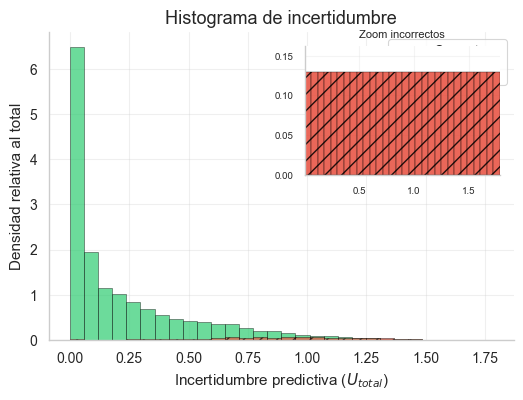

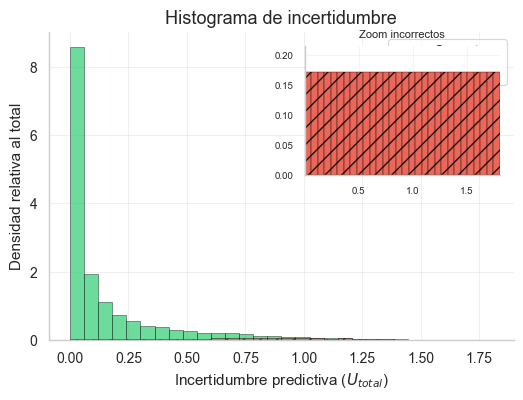

In [23]:
def plot_entropy_histogram(y_true, pred, title="", bins=30):
    entropy = (categorical_entropy(pred)).numpy()
    preds = np.argmax(pred, axis=1)
    correct = np.argmax(y_true, axis=1) == preds
    bin_edges = np.histogram_bin_edges(entropy, bins=bins)

    counts_correct, _ = np.histogram(entropy[correct], bins=bin_edges)
    counts_incorrect, _ = np.histogram(entropy[~correct], bins=bin_edges)
    total = max(len(entropy), 1)
    bin_widths = np.diff(bin_edges)

    correct_density = counts_correct / (total * bin_widths)
    incorrect_density = counts_incorrect / (total * bin_widths)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(
        bin_edges[:-1],
        correct_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Correctos",
        color="#2ecc71",
        edgecolor="black",
        linewidth=0.4,
    )
    ax.bar(
        bin_edges[:-1],
        incorrect_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Incorrectos",
        color="#e74c3c",
        edgecolor="black",
        linewidth=0.4,
        hatch="//",
    )

    ax.set_xlabel("Incertidumbre predictiva ($U_{total}$)")
    ax.set_ylabel("Densidad relativa al total")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

    try:
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        axins = inset_axes(ax, width="42%", height="42%", loc="upper right", borderpad=1)
        max_incorrect = float(incorrect_density.max()) if len(incorrect_density) else 0.0
        min_visible_height = max(max_incorrect * 0.15, float(correct_density.max()) * 0.02 if len(correct_density) else 0.0, 1e-12)
        incorrect_zoom = np.where(incorrect_density > 0, np.maximum(incorrect_density, min_visible_height), 0.0)
        axins.bar(
            bin_edges[:-1],
            incorrect_zoom,
            width=bin_widths,
            align="edge",
            alpha=0.85,
            color="#e74c3c",
            edgecolor="black",
            linewidth=0.3,
            hatch="//",
        )
        axins.set_title("Zoom incorrectos", fontsize=8)
        axins.set_xlim(bin_edges[0], bin_edges[-1])
        axins.set_ylim(0, max(float(incorrect_zoom.max()) * 1.25, min_visible_height * 1.25))
        axins.tick_params(axis="both", labelsize=7)
        axins.grid(True, alpha=0.2)
    except Exception:
        pass

    plt.show()

plot_entropy_histogram(y_test, t_pred, title="Histograma de incertidumbre")
plot_entropy_histogram(y_test, scaled_predictions.astype(np.float32), title="Histograma de incertidumbre")

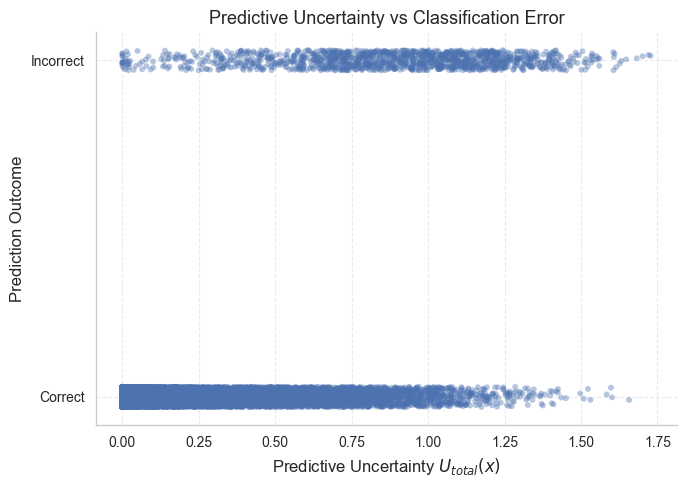

In [31]:
def plot_uncertainty_vs_error(
    u_total,
    y_true,
    p_mean,
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
):
    """
    Scatter plot: U_total vs error (paper-ready)

    Parameters
    ----------
    u_total : np.ndarray (N,)
        Predictive entropy per sample
    y_true : np.ndarray (N,)
        True binary labels
    p_mean : np.ndarray (N,)
        Marginal predicted probabilities
    threshold : float
        Decision threshold
    jitter : float
        Vertical jitter magnitude
    """

    # Predictions
    y_pred = (p_mean >= threshold).astype(int)

    # Error (0 = correct, 1 = incorrect)
    error = (np.argmax(y_pred, axis=1) != np.argmax(y_true, axis=1)).astype(int)

    # Add jitter for visualization
    error_jittered = error + np.random.uniform(
        low=-jitter, high=jitter, size=len(error)
    )

    plt.figure(figsize=figsize)

    plt.scatter(
        u_total,
        error_jittered,
        alpha=0.4,
        s=18,
        edgecolors="none"
    )

    plt.yticks([0, 1], ["Correct", "Incorrect"])
    plt.xlabel("Predictive Uncertainty $U_{total}(x)$", fontsize=12)
    plt.ylabel("Prediction Outcome", fontsize=12)

    plt.title(
        "Predictive Uncertainty vs Classification Error",
        fontsize=13
    )

    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()
plot_uncertainty_vs_error(
    uncertainties[0].numpy(),  # U_total
    y_test,                    # True labels
    t_pred,       # p_mean
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
)

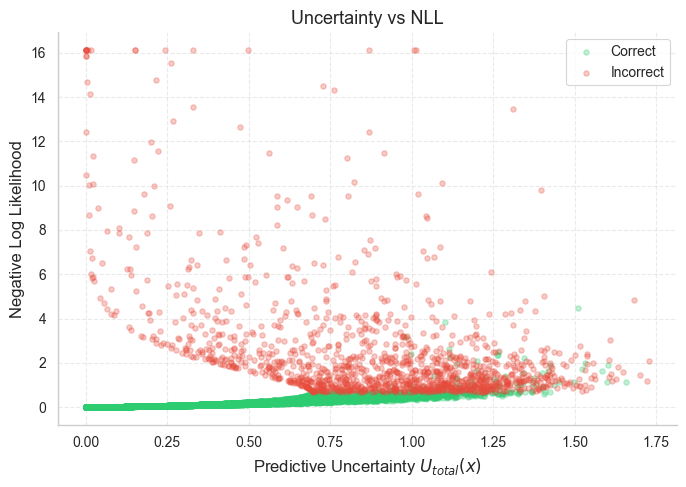

In [32]:
def plot_uncertainty_vs_nll(
    u_total,
    y_true,
    p_mean,
    x_label,
    y_label,
    title,
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
):
    y_pred = (p_mean >= threshold).astype(int)
    loss = tf.keras.losses.categorical_crossentropy(y_true, p_mean)
    correct = (np.argmax(y_pred, axis=1) == np.argmax(y_true, axis=1)).astype(bool)
    incorrect = ~correct.astype(bool)

    # Scatter
    plt.figure(figsize=figsize)
    plt.scatter(
        u_total[correct],
        loss[correct],
        color='#2ecc71',
        alpha=0.3,
        s=15,
        label="Correct"
    )
    plt.scatter(
        u_total[incorrect],
        loss[incorrect],
        color='#e74c3c',
        alpha=0.3,
        s=15,
        label="Incorrect"
    )

    

    plt.xlabel(x_label, fontsize=12)
    plt.ylabel(y_label, fontsize=12)
    plt.title(title, fontsize=13)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

plot_uncertainty_vs_nll(
    uncertainties[0].numpy(),
    y_test,
    t_pred,
    x_label="Predictive Uncertainty $U_{total}(x)$",
    y_label="Negative Log Likelihood",
    title="Uncertainty vs NLL",
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
)


In [33]:
from scipy.stats import spearmanr
loss = tf.keras.losses.categorical_crossentropy(y_test, t_pred)
rho, p_value = spearmanr(uncertainties[0].numpy(), loss)
print(f"Spearman ρ = {rho:.3f}, p-value = {p_value:.2e}")

Spearman ρ = 0.989, p-value = 0.00e+00


In [34]:
y_pred = (scaled_predictions >= 0.5).astype(int)

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

In [36]:
y_test = np.argmax(y_test, axis=1)
y_pred = np.argmax(y_pred, axis=1)

In [37]:
y_pred = np.argmax((t_pred >= 0.5).astype(int), axis=1)

Precision test: 0.9353
Recall test: 0.9271
AUC test: 0.9934
F1-score test: 0.9299
Clasification report test:
              precision    recall  f1-score   support

           0       0.78      0.93      0.85      2261
           1       0.95      0.94      0.94      6759
           2       0.94      0.90      0.92      3453
           3       0.96      0.90      0.93      1913
           4       0.96      0.90      0.93      1196
           5       0.97      0.96      0.96      2263
           6       0.98      0.96      0.97       737

    accuracy                           0.93     18582
   macro avg       0.94      0.93      0.93     18582
weighted avg       0.93      0.93      0.93     18582



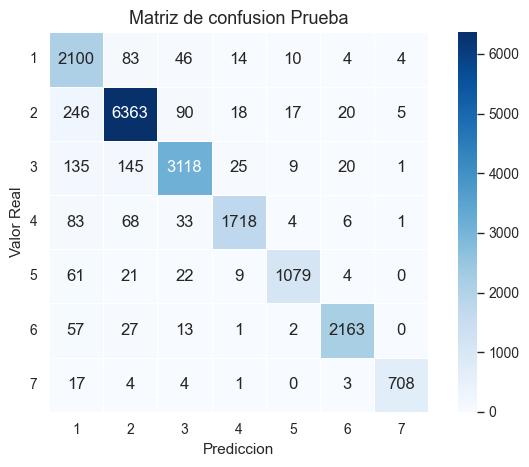

In [37]:
precision_v = precision_score(y_test, y_pred, average='macro')
recall_v = recall_score(y_test, y_pred, average='macro')
roc_auc_v = roc_auc_score(np.eye(num_class)[y_test], scaled_predictions)
f1_v = f1_score(y_test, y_pred, average='macro')
conf_matrix_v = confusion_matrix(y_test, y_pred)
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_test, y_pred), sep=f'\n')
class_labels = [1, 2, 3, 4, 5, 6, 7]
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')

### Validar como aumentan las medidas de calidad a medida que se van eliminando las secuencias de más incertidumbre

In [38]:
u_total = uncertainties[0].numpy()

In [39]:
index = np.array([i for i in range(len(u_total))])
combined = np.concatenate((u_total, index.reshape(-1, 1)), axis=1)

In [40]:
sorted_u = combined[combined[:,0].argsort()[::-1]]

#### Para el 5%

In [41]:
percent = 5
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [42]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [43]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [53]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = tf.nn.softmax(scaler(f_logits), axis=-1).numpy()

In [54]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [55]:
y_pred_f = np.argmax(y_pred_f, axis=1)

In [56]:
precision_v = precision_score(y_filter, y_pred_f, average='macro')
recall_v = recall_score(y_filter, y_pred_f, average='macro')
roc_auc_v = roc_auc_score(np.eye(num_class)[y_filter], f_scaled_predictions)
f1_v = f1_score(y_filter, y_pred_f, average='macro')
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Precision test: 0.9610
Recall test: 0.9557
AUC test: 0.9955
F1-score test: 0.9582
Clasification report test:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92      2108
           1       0.96      0.97      0.96      6441
           2       0.95      0.93      0.94      3273
           3       0.97      0.94      0.95      1814
           4       0.98      0.95      0.96      1091
           5       0.98      0.98      0.98      2204
           6       0.99      0.97      0.98       722

    accuracy                           0.96     17653
   macro avg       0.96      0.96      0.96     17653
weighted avg       0.96      0.96      0.96     17653



#### Para el 10%

In [57]:
percent = 10
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [58]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [59]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [60]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = tf.nn.softmax(scaler(f_logits), axis=-1).numpy()

In [61]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [62]:
y_pred_f = np.argmax(y_pred_f, axis=1)

In [63]:
precision_v = precision_score(y_filter, y_pred_f, average='macro')
recall_v = recall_score(y_filter, y_pred_f, average='macro')
roc_auc_v = roc_auc_score(np.eye(num_class)[y_filter], f_scaled_predictions)
f1_v = f1_score(y_filter, y_pred_f, average='macro')
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Precision test: 0.9768
Recall test: 0.9720
AUC test: 0.9966
F1-score test: 0.9743
Clasification report test:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      1989
           1       0.97      0.98      0.98      6116
           2       0.97      0.96      0.96      3046
           3       0.98      0.96      0.97      1711
           4       0.99      0.97      0.98      1015
           5       0.99      0.99      0.99      2145
           6       0.99      0.98      0.99       702

    accuracy                           0.97     16724
   macro avg       0.98      0.97      0.97     16724
weighted avg       0.97      0.97      0.97     16724



#### Para el 20%

In [64]:
percent = 20
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [65]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [66]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [67]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = tf.nn.softmax(scaler(f_logits), axis=-1).numpy()

In [68]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [69]:
y_pred_f = np.argmax(y_pred_f, axis=1)

In [70]:
precision_v = precision_score(y_filter, y_pred_f, average='macro')
recall_v = recall_score(y_filter, y_pred_f, average='macro')
roc_auc_v = roc_auc_score(np.eye(num_class)[y_filter], f_scaled_predictions)
f1_v = f1_score(y_filter, y_pred_f, average='macro')
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Precision test: 0.9899
Recall test: 0.9874
AUC test: 0.9979
F1-score test: 0.9886
Clasification report test:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1724
           1       0.99      0.99      0.99      5410
           2       0.99      0.98      0.98      2658
           3       0.99      0.98      0.99      1522
           4       1.00      0.99      0.99       874
           5       1.00      1.00      1.00      2015
           6       1.00      0.99      0.99       663

    accuracy                           0.99     14866
   macro avg       0.99      0.99      0.99     14866
weighted avg       0.99      0.99      0.99     14866

